# Avance 2: análisis de asociaciones y modelamiento estadístico

Proyecto: factores asociados a la duración y las estadías prolongadas en beneficiarios FONASA (Chile, 2020)

**Resumen.** Estudio observacional retrospectivo de los 968.098 egresos FONASA de 2020 incluidos en el Avance 1. Analizamos la duración mediante regresión lineal múltiple de ln(días) y la ocurrencia de estadías de más de 15 días mediante regresión logística. Todos los modelos se estiman con la base completa: no se realizan particiones de la base.

El objetivo es describir asociaciones ajustadas, contrastar las hipótesis de investigación y cuantificar su magnitud. Conservamos los siete factores seleccionados por BIC en el Avance 1. Comparamos bloques clínicos, demográficos y del sistema de salud; examinamos especificaciones alternativas de edad e interacciones y revisamos los supuestos. Los coeficientes, intervalos y tamaños de efecto son el centro de la interpretación; las medidas de ajuste describen únicamente los datos analizados.

Los resultados recalculados se presentan en las tablas y figuras. La significación estadística no equivale a relevancia práctica ni a causalidad. Los intervalos y contrastes dependen de los supuestos del modelo, y no representan validación para otros años o pacientes.

Fuente de todas las tablas y figuras: DEIS (MINSAL), egresos hospitalarios 2020; elaboración propia.

**Hallazgos principales.** En la base completa, M3 tiene R² ajustado de 0,198. Diagnóstico, establecimiento y edad concentran los mayores aportes ajustados. La asociación de SNSS corresponde a 70,0 % más de media geométrica de días y OR = 2,54 para estadía prolongada. Las especificaciones alternativas elevan el R² ajustado hasta 0,215; el ajuste restante sigue siendo limitado.

## 1. Pregunta de investigación e hipótesis

La pregunta y las hipótesis son las del Avance 1.

> ¿Qué factores clínicos, demográficos y del sistema de salud se asocian con la duración de la estadía y con las estadías prolongadas (más de 15 días) en los egresos FONASA de Chile en 2020?

**Hipótesis general**

- H₀: la duración de la estadía y la ocurrencia de estadías prolongadas no se asocian con los factores clínicos, demográficos ni del sistema de salud.
- H₁: al menos uno de esos factores se asocia con la duración de la estadía o con la ocurrencia de estadías prolongadas.

Hipótesis específicas, una por grupo de factores:

| | Factores | H₁ |
|---|---|---|
| H1a | Clínicos: capítulo del diagnóstico (CIE-10), cirugía y condición de egreso | Se asocian a la duración y a la estadía prolongada |
| H1b | Demográficos: edad, sexo, nacionalidad y etnia | Se asocian a la duración y a la estadía prolongada (esperamos más días a mayor edad) |
| H1c | Sistema de salud: tipo de establecimiento y región | Se asocian a la duración y a la estadía prolongada |

Qué cambia respecto del Avance 1: pasamos de asociaciones bivariadas a asociaciones ajustadas por los demás factores. La regresión lineal aborda la duración y la logística la ocurrencia de estadías prolongadas. Nacionalidad y etnia quedaron fuera por BIC; revisamos su incorporación como análisis de sensibilidad. Para la duración usamos significación y η² parcial ≥ 0,01 como criterio orientativo de relevancia; en la logística interpretamos OR, intervalos y caída del pseudo-R² de McFadden al retirar factores.

## 2. Exploración y preparación de los datos

Seguimos las cinco etapas del curso: análisis descriptivo, ajuste de variables, valores nulos, valores atípicos y relación entre variables.

### Paso 1: cargar los datos

Incluimos FONASA (`PREVISION = 1`) y estadías de hasta 365 días, manteniendo el criterio del Avance 1. Se excluyen 397 registros de más de un año por la regla de depuración adoptada; la duración por sí sola no demuestra que todos sean errores. Se conservan las estadías largas dentro del rango definido porque forman parte del fenómeno de interés.

In [1]:
import os
import json
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats
from IPython.display import Markdown, display
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.outliers_influence import variance_inflation_factor

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
teal, petroleo, coral = "#0E7C7A", "#0F2A33", "#D9534F"

with zipfile.ZipFile("data/raw/EGRESOS_2020.zip") as z:
    df = pd.read_csv(z.open("EGRE_DATOS_ABIERTOS_2020.csv"), sep=";", encoding="cp1252", dtype=str)
print("Egresos 2020:", len(df))

df = df[df["PREVISION"] == "1"]                      # solo FONASA
df["dias_estada"] = pd.to_numeric(df["DIAS_ESTADA"])
bruta = df["dias_estada"].copy()                     # con los de más de 365 días, para compararlos en la etapa 4
print("Estadías de más de 365 días:", (df["dias_estada"] > 365).sum(), "| máximo:", df["dias_estada"].max(), "días")
df = df[df["dias_estada"] <= 365].copy()             # quitamos errores de registro
print("Egresos FONASA con estada <= 365 días:", len(df))

Egresos 2020: 1330477


Estadías de más de 365 días: 397 | máximo: 16598 días
Egresos FONASA con estada <= 365 días: 968098


Quedan 968.098 egresos, el mismo número del Avance 1.

### Paso 2: construir las variables

Reutilizamos los mapeos del Avance 1: la edad es el punto medio de cada tramo, el capítulo CIE-10 viene del diccionario del DEIS, `INTERV_Q` 1/2 es cirugía Sí/No y `CONDICION_EGRESO` 1/2 es vivo/fallecido. Nos quedamos con la respuesta, los 7 predictores y `DIAG2` (para revisar sus nulos), y agregamos ln(días).

In [2]:
edad_media = {"menor de un año": 0.5, "1 a 9": 5, "10 a 19": 14.5, "20 a 29": 24.5, "30 a 39": 34.5,
              "40 a 49": 44.5, "50 a 59": 54.5, "60 a 69": 64.5, "70 a 79": 74.5, "80 a 89": 84.5,
              "90 y más": 92.5}
cie = pd.read_excel("data/raw/x2020/Diccionario BD egresos hospitalario.xlsx", "codigo CIE-10", header=8)
cie.columns = cie.columns.str.strip()

df["prolongada"] = np.where(df["dias_estada"] > 15, "Sí", "No")
df["edad"] = df["GRUPO_EDAD"].map(edad_media)
df["tramo_edad"] = df["GRUPO_EDAD"]
df["sexo"] = df["SEXO"]
df["capitulo"] = df["DIAG1"].map(dict(zip(cie["CODIGO SUBCATEGORIA"], cie["CAPITULO"])))
df["capitulo"] = df["capitulo"].fillna(df["DIAG1"].str[:3].map(dict(zip(cie["CODIGO CATEGORIA"], cie["CAPITULO"]))))
df["cirugia"] = df["INTERV_Q"].map({"1": "Sí", "2": "No"})
df["fallecido"] = df["CONDICION_EGRESO"].map({"1": "No", "2": "Sí"})
df["establecimiento"] = np.where(df["PERTENENCIA_ESTABLECIMIENTO_SALUD"].str.startswith("Pert"), "SNSS", "No SNSS")
df["region"] = df["GLOSA_REGION_RESIDENCIA"]
df["nacionalidad"] = df["GLOSA_PAIS_ORIGEN"]
df["etnia"] = np.where(df["ETNIA"].str.startswith("Si"), "Sí", "No")
df["log_dias"] = np.log(df["dias_estada"])

variables = ["dias_estada", "log_dias", "prolongada", "edad", "tramo_edad", "sexo", "capitulo", "cirugia",
             "fallecido", "establecimiento", "region", "nacionalidad", "etnia", "DIAG2"]
df = df[variables]
print("Egresos:", len(df), "| columnas:", df.shape[1])
df.head()

Egresos: 968098 | columnas: 14


,dias_estada,log_dias,prolongada,edad,tramo_edad,sexo,capitulo,cirugia,fallecido,establecimiento,region,nacionalidad,etnia,DIAG2
0,1,0.0,No,5.0,1 a 9,HOMBRE,Q00-Q99,Sí,No,No SNSS,De Tarapacá,Chileno,No,NaN
1,1,0.0,No,5.0,1 a 9,HOMBRE,Q00-Q99,Sí,No,No SNSS,De Tarapacá,Chileno,No,NaN
2,1,0.0,No,5.0,1 a 9,HOMBRE,Z00-Z99,Sí,No,No SNSS,De Tarapacá,Chileno,No,NaN
3,1,0.0,No,5.0,1 a 9,HOMBRE,N00-N99,Sí,No,No SNSS,De Tarapacá,Chileno,No,NaN
4,1,0.0,No,5.0,1 a 9,HOMBRE,N00-N99,Sí,No,No SNSS,De Tarapacá,Chileno,No,NaN


### Etapa 1: análisis descriptivo

**Tabla 1.** Estadísticos descriptivos de los días de estada, ln(días) y la edad. Fuente: DEIS, MINSAL, egresos hospitalarios 2020; elaboración propia.

In [3]:
cols = ["dias_estada", "log_dias", "edad"]
desc = df[cols].agg(["count", "mean", "median"]).T
desc["Q1"] = df[cols].quantile(0.25)
desc["Q3"] = df[cols].quantile(0.75)
desc["RIC"] = desc["Q3"] - desc["Q1"]
desc["s"] = df[cols].std()
desc["CV"] = desc["s"] / desc["mean"]
desc["asimetría"] = df[cols].skew()
desc.round(2)

,count,mean,median,Q1,Q3,RIC,s,CV,asimetría
dias_estada,968098.0,6.70,3.0,2.00,7.00,5.00,12.79,1.91,9.04
log_dias,968098.0,1.25,1.1,0.69,1.95,1.25,1.04,0.83,0.68
edad,968098.0,45.01,44.5,24.50,64.50,40.00,24.29,0.54,0.01


Los días de estada tienen media 6,70 y mediana 3 (Q1 = 2, Q3 = 7, RIC = 5). La desviación estándar (12,79) casi duplica la media (CV = 1,91) y la asimetría es 9,04: la mayoría dura pocos días y unos pocos duran muchísimo. En ln(días) la asimetría baja a 0,68 y la media (1,25) queda cerca de la mediana (1,10), por eso modelamos el logaritmo. La edad es simétrica (asimetría 0,01; media 45,01; mediana 44,5; Q1 = 24,5; Q3 = 64,5).

In [4]:
for var in ["establecimiento", "sexo"]:
    print((100 * df[var].value_counts(normalize=True)).round(1).to_string(), "\n")
cap = 100 * df["capitulo"].value_counts(normalize=True)
print("Capítulos más frecuentes (%):")
print(cap.head(6).round(1).to_string())
print(f"Los otros {len(cap) - 6} capítulos juntos:", round(cap.iloc[6:].sum(), 1), "%")

establecimiento
SNSS       81.8
No SNSS    18.2 



sexo
MUJER     60.0
HOMBRE    40.0 

Capítulos más frecuentes (%):
capitulo
O00-O99    20.4
K00-K93    13.8
S00-T98     9.8
I00-I99     9.3
N00-N99     7.6
C00-D48     7.4
Los otros 15 capítulos juntos: 31.7 %


El 81,8 % de los egresos son de establecimientos del SNSS y el 60,0 % son mujeres. Los capítulos más frecuentes son embarazo, parto y puerperio (O00-O99, 20,4 %), digestivo (K00-K93, 13,8 %) y traumatismos (S00-T98, 9,8 %). Los otros 15 suman el 31,7 %.

**Figura 1.** Distribución de los días de estada (izquierda, recortada a 60 días), de ln(días) (centro) y curva de concentración de los días-cama (derecha).

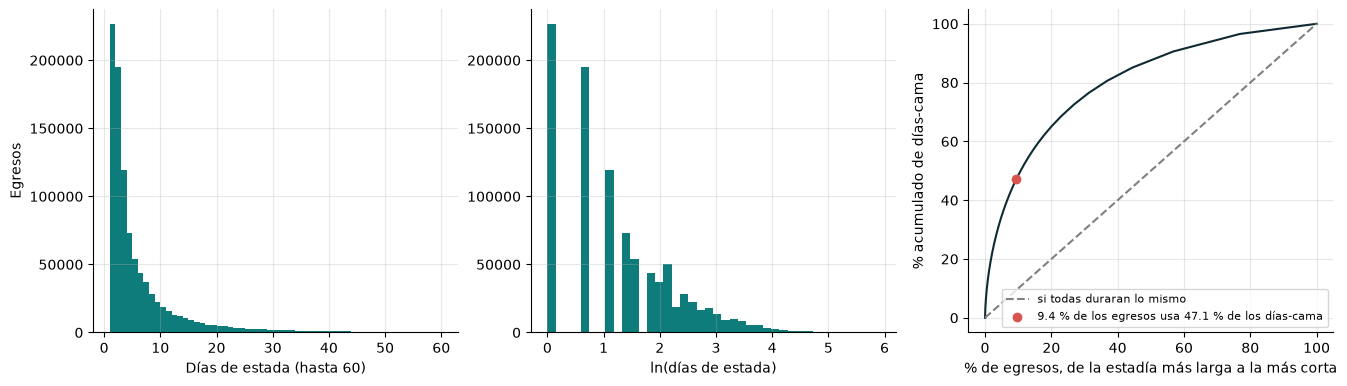

Media: 6.7 | mediana: 3.0 | egresos prolongados: 9.4 % | días-cama que usan: 47.1 %


In [5]:
largas = df["prolongada"] == "Sí"
pct_egresos = 100 * largas.mean()
pct_dias = 100 * df.loc[largas, "dias_estada"].sum() / df["dias_estada"].sum()

orden = np.sort(df["dias_estada"].values)[::-1]                 # de la estadía más larga a la más corta
x_conc = 100 * np.arange(1, len(orden) + 1) / len(orden)
y_conc = 100 * orden.cumsum() / orden.sum()

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
ax[0].hist(df["dias_estada"], bins=range(1, 61), color=teal)
ax[0].set_xlabel("Días de estada (hasta 60)")
ax[0].set_ylabel("Egresos")
ax[1].hist(df["log_dias"], bins=40, color=teal)
ax[1].set_xlabel("ln(días de estada)")
ax[2].plot(x_conc[::500], y_conc[::500], color=petroleo)
ax[2].plot([0, 100], [0, 100], color="gray", linestyle="--", label="si todas duraran lo mismo")
ax[2].scatter([pct_egresos], [pct_dias], color=coral, zorder=3,
              label=f"{pct_egresos:.1f} % de los egresos usa {pct_dias:.1f} % de los días-cama")
ax[2].set_xlabel("% de egresos, de la estadía más larga a la más corta")
ax[2].set_ylabel("% acumulado de días-cama")
ax[2].legend(loc="lower right", fontsize=8)
os.makedirs("figures/avance2_analitico", exist_ok=True)
fig.savefig("figures/avance2_analitico/avance2_distribucion.png", dpi=200, bbox_inches="tight")
plt.show()
print("Media:", round(df["dias_estada"].mean(), 1), "| mediana:", df["dias_estada"].median(),
      "| egresos prolongados:", round(pct_egresos, 1), "% | días-cama que usan:", round(pct_dias, 1), "%")

El histograma de días tiene cola larga: la moda es 1 día (226.248 egresos), seguida de 2 días (194.873) y 3 días (119.440). En ln(días) las barras quedan separadas porque los días son enteros (ln 1 = 0, ln 2 = 0,69, ln 3 = 1,10), y la cola derecha es más corta. La curva de la derecha muestra que el 9,4 % de los egresos (los de más de 15 días) usa el 47,1 % de los días-cama (estadías de hasta 365 días). Esos pocos egresos largos pesan mucho en la gestión de camas, así que queremos entender qué se asocia con la duración.

### Etapa 2: ajuste de variables

| Variable | Tipo | Codificación | Referencia |
|---|---|---|---|
| ln(días) | Numérica, respuesta | Logaritmo natural de `DIAS_ESTADA` | |
| Edad | Numérica | `edad_c` = punto medio del tramo − media, y `edad_c`² | Edad media (0) |
| Capítulo CIE-10 | Categórica (21) | 20 indicadoras | K00-K93 |
| Cirugía | Categórica | Indicadora de Sí | No |
| Condición de egreso | Categórica | Indicadora de fallecido | Vivo |
| Sexo | Categórica | Indicadora de hombre | Mujer |
| Establecimiento | Categórica | Indicadora de SNSS | No SNSS |
| Región | Categórica (16) | 15 indicadoras | Metropolitana de Santiago |

En el Avance 1 centramos la edad en 50 para que edad y edad² no quedaran colineales en la selección por BIC. Aquí la centramos en su media, así el intercepto corresponde a un paciente de edad promedio. Es solo un cambio de origen y el ajuste es el mismo.

En sexo la referencia es la mujer, para expresar el coeficiente como hombres frente a mujeres. Así respondemos lo que el Avance 1 dejó pendiente: si la diferencia por sexo se mantiene al controlar por diagnóstico. La asociación ajustada se estima en 3.3 con la base completa. Cambiar la referencia solo cambia el signo y la lectura del coeficiente.

Como capítulo de referencia usamos K00-K93 en vez de O00-O99, que en el Avance 1 usamos solo para la selección. O00-O99 contiene solo mujeres. K00-K93 ofrece una referencia clínicamente común en ambos sexos; cambiar la referencia no modifica el ajuste ni resuelve por sí mismo la asociación entre sexo y capítulo. K00-K93 tiene hombres y mujeres y una mediana baja (2 días), así que los demás coeficientes son diferencias respecto de un egreso corto y habitual.

In [6]:
edad_prom = df["edad"].mean()
df["edad_c"] = df["edad"] - edad_prom
print("Edad media (el cero de edad_c):", round(edad_prom, 2))
k = df[df["capitulo"] == "K00-K93"]
print("Capítulo K00-K93:", round(100 * len(k) / len(df), 1), "% de los egresos | mediana:", k["dias_estada"].median(),
      "días | sexo (% mujeres):", round(100 * (k["sexo"] == "MUJER").mean(), 1))
print("Valores de sexo:", sorted(df["sexo"].unique()))

Edad media (el cero de edad_c): 45.01
Capítulo K00-K93: 13.8 % de los egresos | mediana: 2.0 días | sexo (% mujeres): 53.6
Valores de sexo: ['HOMBRE', 'MUJER']


La edad media es 45,01 años. K00-K93 es el 13,8 % de los egresos, con una mediana de 2 días y un 53,6 % de mujeres, así que sirve como referencia para interpretar comparaciones.

### Etapa 3: valores nulos

In [7]:
usadas = ["dias_estada", "edad", "sexo", "capitulo", "cirugia", "fallecido", "establecimiento", "region", "DIAG2"]
print(df[usadas].isna().sum().to_string())
pct_diag2 = 100 * df["DIAG2"].isna().mean()
print("DIAG2 nulo:", round(pct_diag2, 1), "% de los egresos")

dias_estada             0
edad                    0
sexo                    0
capitulo                0
cirugia                 0
fallecido               0
establecimiento         0
region                  0
DIAG2              872823
DIAG2 nulo: 90.2 % de los egresos


Las variables de la respuesta y de los 7 predictores no tienen nulos, así que no imputamos ni eliminamos egresos. `DIAG2` tiene un 90,2 % de nulos. En el Avance 1 vimos que solo aparece en el capítulo S00-T98, con una V de Cramér de 1,00: repite información del capítulo. Por eso la descartamos.

### Etapa 4: valores atípicos

Usamos el criterio de Tukey (Ls = Q3 + 1,5·RIC) y el de |z| > 3, sobre días y ln(días). Comparamos también media y desviación estándar con mediana y MAD (mediana de las desviaciones absolutas respecto de la mediana), antes y después del filtro de 365 días.

**Tabla 2.** Límites de Tukey y de |z| > 3 para los días y ln(días) (primera salida). **Tabla 3.** Media, desviación estándar, mediana y MAD antes y después de excluir los egresos de más de 365 días (segunda salida). Fuente: DEIS, MINSAL, egresos hospitalarios 2020; elaboración propia.

In [8]:
filas = []
for nombre, x in [("días", df["dias_estada"]), ("ln(días)", df["log_dias"])]:
    q1, q3 = x.quantile([0.25, 0.75])
    li, ls = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    z = (x - x.mean()) / x.std()
    filas.append({"variable": nombre, "Li": li, "Ls": ls, "n > Ls": (x > ls).sum(), "% > Ls": 100 * (x > ls).mean(),
                  "n < Li": (x < li).sum(), "n |z| > 3": (z.abs() > 3).sum(), "% |z| > 3": 100 * (z.abs() > 3).mean()})
atip = pd.DataFrame(filas).set_index("variable")
print(atip.round(2).to_string())

comp = pd.DataFrame({"n": [len(bruta), len(df), len(df)]}, index=["días con > 365 incluidos", "días (base final)", "ln(días)"])
series = [bruta, df["dias_estada"], df["log_dias"]]
comp["media"] = [x.mean() for x in series]
comp["s"] = [x.std() for x in series]
comp["mediana"] = [x.median() for x in series]
comp["MAD"] = [(x - x.median()).abs().median() for x in series]
comp.round(2)

            Li     Ls  n > Ls  % > Ls  n < Li  n |z| > 3  % |z| > 3
variable                                                           
días     -5.50  14.50   99978   10.33       0      14614       1.51
ln(días) -1.19   3.83   14614    1.51       0       4745       0.49


,n,media,s,mediana,MAD
días con > 365 incluidos,968495,7.29,59.74,3.0,2.00
días (base final),968098,6.70,12.79,3.0,2.00
ln(días),968098,1.25,1.04,1.1,0.69


Con Tukey, el límite superior de los días es 14,5 y lo superan 99.978 egresos (10,33 %). Con |z| > 3 son 14.614 (1,51 %). En ln(días) el límite sube a 3,83 (unos 46 días) y lo superan 14.614 egresos (1,51 %); con |z| > 3 son 4.745 (0,49 %). Por abajo no hay ninguno, porque el mínimo es 1 día. Que en ln(días) sigan apareciendo atípicos según Tukey se debe a que la cola derecha sigue siendo más larga.

La comparación muestra por qué filtramos los 397 egresos de más de 365 días: con ellos, la media sube de 6,70 a 7,29 y la desviación estándar de 12,79 a 59,74, mientras la mediana (3) y el MAD (2) no cambian. Unos pocos registros extremadamente largos mueven la media y s, pero no las medidas basadas en la mediana.

**Figura 2.** Diagrama de caja de los días de estada (izquierda) y de ln(días) (derecha). La línea roja marca Q3 + 1,5·RIC.

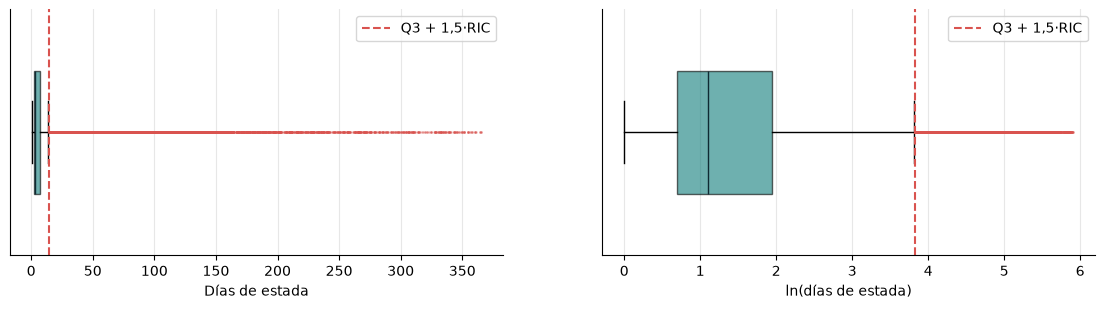

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(14, 3.2))
for a, col, titulo in zip(ax, ["dias_estada", "log_dias"], ["Días de estada", "ln(días de estada)"]):
    a.boxplot(df[col], orientation="horizontal", widths=0.5, patch_artist=True,
              boxprops=dict(facecolor=teal, alpha=0.6), medianprops=dict(color=petroleo),
              flierprops=dict(marker=".", markersize=2, markerfacecolor=coral, markeredgecolor=coral, alpha=0.3))
    a.axvline(atip.loc["días" if col == "dias_estada" else "ln(días)", "Ls"], color=coral, linestyle="--", label="Q3 + 1,5·RIC")
    a.set_xlabel(titulo)
    a.set_yticks([])
    a.legend()
fig.savefig("figures/avance2_analitico/avance2_atipicos.png", dpi=200, bbox_inches="tight")
plt.show()

En días, la caja está pegada a la izquierda y los puntos rojos llegan hasta 365 días, el máximo que dejamos. En ln(días) la caja es simétrica y los puntos forman una cola más corta. Conservamos los egresos de 15 a 365 días porque las estadías largas forman parte del fenómeno estudiado. Excluimos los de más de 365 días conforme al criterio del Avance 1; el máximo registrado es 16.598 días (unos 45 años). El filtro no demuestra que todos los registros excluidos sean erróneos. Modelamos ln(días), que reduce la influencia de estos valores en los coeficientes, y revisamos sus residuos en 3.6.

### Etapa 5: relación entre variables

Antes de ver si los predictores se repiten entre sí, miramos cómo cambia ln(días) según los tres factores con más diferencia en el Avance 1: capítulo, establecimiento y sexo.

C:\Users\super\AppData\Local\Temp\ipykernel_1348\4081321866.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax0.boxplot([df.loc[df["capitulo"] == k, "log_dias"] for k in orden_cap], vert=False, showfliers=False,
C:\Users\super\AppData\Local\Temp\ipykernel_1348\4081321866.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot([df.loc[df[col] == n, "log_dias"] for n in niv], vert=False, showfliers=False,
C:\Users\super\AppData\Local\Temp\ipykernel_1348\4081321866.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot([df.loc[df[col] == n, "log_dias"] for n in niv], vert=False, showfliers=False,


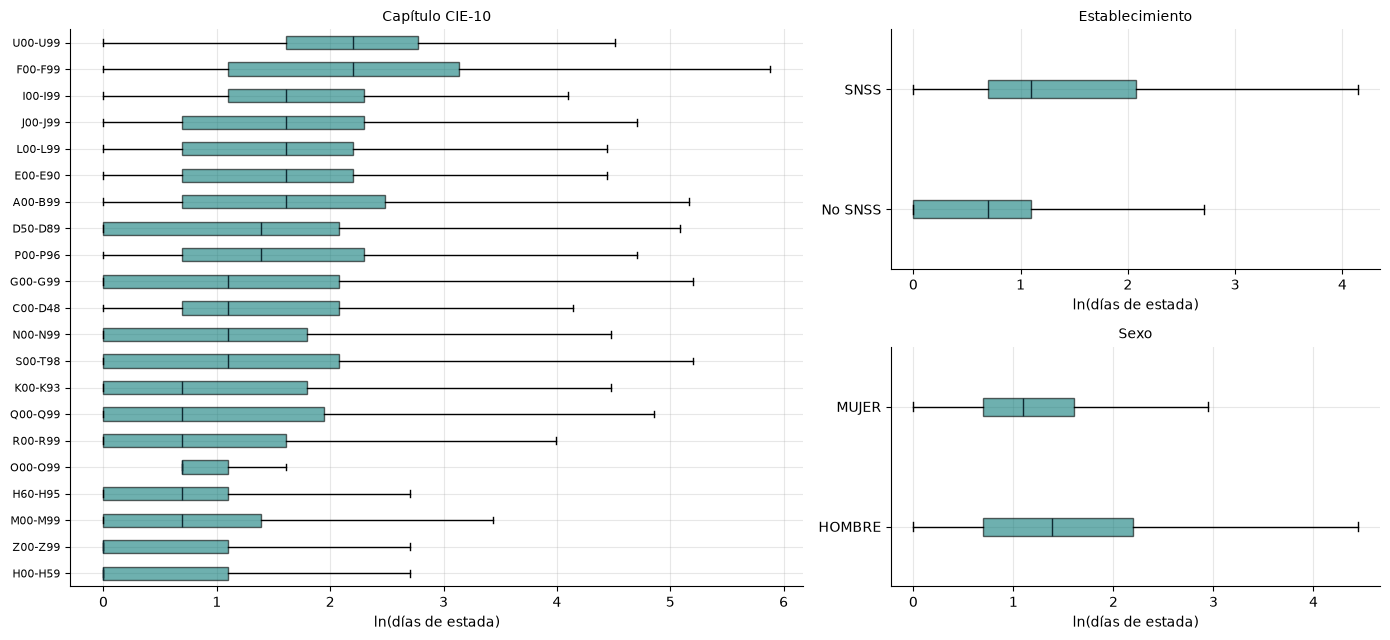

Mediana de días por capítulo: mínima 1.0 (H00-H59), máxima 9.0 (U00-U99)
Mediana de días por establecimiento: {'No SNSS': 2.0, 'SNSS': 3.0}
Mediana de días por sexo: {'HOMBRE': 4.0, 'MUJER': 3.0}
Mediana de días por cirugía: {'No': 4.0, 'Sí': 2.0} | por condición de egreso: {'No': 3.0, 'Sí': 7.0}


In [10]:
orden_cap = df.groupby("capitulo")["log_dias"].median().sort_values().index
fig = plt.figure(figsize=(14, 6.5))
gs = fig.add_gridspec(2, 2, width_ratios=[1.5, 1])
ax0 = fig.add_subplot(gs[:, 0])
ax0.boxplot([df.loc[df["capitulo"] == k, "log_dias"] for k in orden_cap], vert=False, showfliers=False,
            patch_artist=True, boxprops=dict(facecolor=teal, alpha=0.6), medianprops=dict(color=petroleo))
ax0.set_yticks(range(1, len(orden_cap) + 1), orden_cap, fontsize=8)
ax0.set_xlabel("ln(días de estada)")
ax0.set_title("Capítulo CIE-10", fontsize=10)
for ax, col, tit in [(fig.add_subplot(gs[0, 1]), "establecimiento", "Establecimiento"),
                     (fig.add_subplot(gs[1, 1]), "sexo", "Sexo")]:
    niv = sorted(df[col].unique())
    ax.boxplot([df.loc[df[col] == n, "log_dias"] for n in niv], vert=False, showfliers=False,
               patch_artist=True, boxprops=dict(facecolor=teal, alpha=0.6), medianprops=dict(color=petroleo))
    ax.set_yticks(range(1, len(niv) + 1), niv)
    ax.set_xlabel("ln(días de estada)")
    ax.set_title(tit, fontsize=10)
fig.tight_layout()
fig.savefig("figures/avance2_analitico/avance2_bivariado.png", dpi=200, bbox_inches="tight")
plt.show()
med = df.groupby("capitulo")["dias_estada"].median().sort_values()
print("Mediana de días por capítulo: mínima", med.iloc[0], "(" + med.index[0] + "), máxima", med.iloc[-1], "(" + med.index[-1] + ")")
print("Mediana de días por establecimiento:", df.groupby("establecimiento")["dias_estada"].median().to_dict())
print("Mediana de días por sexo:", df.groupby("sexo")["dias_estada"].median().to_dict())
print("Mediana de días por cirugía:", df.groupby("cirugia")["dias_estada"].median().to_dict(),
      "| por condición de egreso:", df.groupby("fallecido")["dias_estada"].median().to_dict())

**Figura 3.** Distribución de ln(días) por capítulo CIE-10 (ordenados por mediana), por tipo de establecimiento y por sexo. Sin puntos atípicos, para ver las cajas. Fuente: DEIS, MINSAL, egresos hospitalarios 2020; elaboración propia.

Las cajas se mueven bastante entre capítulos: la mediana de días va de 1 (H00-H59, ojo) a 9 (U00-U99, uso especial), y la de F00-F99 queda también arriba. Entre establecimientos la diferencia es más corta (mediana de 3 días en el SNSS contra 2 fuera del SNSS), y entre sexos también (4 días en hombres contra 3 en mujeres). Esto anticipa el orden del modelo: el capítulo separa mucho más los egresos que el establecimiento o el sexo. Cirugía y condición de egreso tienen medianas de 2 y 4 días (con y sin cirugía) y de 7 y 3 días (fallecido y vivo), pero la mayor parte de esa diferencia se achica al controlar por el diagnóstico (3.7).

Para ver si los predictores categóricos se repiten entre sí, calculamos la V de Cramér entre todos los pares. La edad queda fuera por ser numérica.

capitulo  cirugia            0.429
          sexo               0.428
cirugia   establecimiento    0.283
capitulo  fallecido          0.261
          establecimiento    0.190
% de egresos con cirugía por capítulo: mínimo 0.7 (F00-F99), máximo 75.0 (M00-M99)
% de mujeres en O00-O99: 100.0


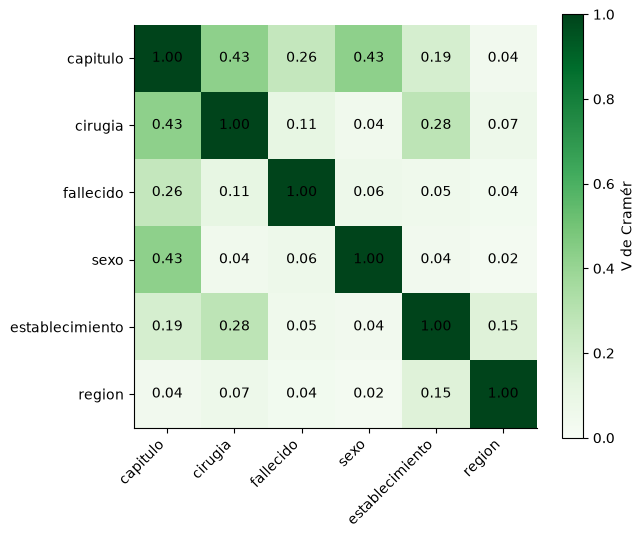

In [11]:
cats = ["capitulo", "cirugia", "fallecido", "sexo", "establecimiento", "region"]
V = pd.DataFrame(1.0, index=cats, columns=cats)
for i, a in enumerate(cats):
    for b in cats[i + 1:]:
        tabla = pd.crosstab(df[a], df[b])
        chi2 = stats.chi2_contingency(tabla)[0]
        V.loc[a, b] = V.loc[b, a] = np.sqrt(chi2 / (len(df) * (min(tabla.shape) - 1)))

pares = V.where(~np.eye(len(cats), dtype=bool)).stack()
pares = pares[[a < b for a, b in pares.index]].sort_values(ascending=False)
print(pares.round(3).head(5).to_string())
cir = 100 * df.groupby("capitulo")["cirugia"].apply(lambda s: (s == "Sí").mean())
print("% de egresos con cirugía por capítulo: mínimo", round(cir.min(), 1), "(" + cir.idxmin() + "), máximo", round(cir.max(), 1), "(" + cir.idxmax() + ")")
print("% de mujeres en O00-O99:", round(100 * (df.loc[df["capitulo"] == "O00-O99", "sexo"] == "MUJER").mean(), 1))

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(V, cmap="Greens", vmin=0, vmax=1)
ax.set_xticks(range(len(cats)), cats, rotation=45, ha="right")
ax.set_yticks(range(len(cats)), cats)
for i in range(len(cats)):
    for j in range(len(cats)):
        ax.text(j, i, f"{V.iloc[i, j]:.2f}", ha="center", va="center", color="black")
ax.grid(False)
fig.colorbar(im, label="V de Cramér")
fig.savefig("figures/avance2_analitico/avance2_cramer.png", dpi=200, bbox_inches="tight")
plt.show()

**Figura 4.** V de Cramér entre los predictores categóricos.

El máximo es 0,43 (capítulo y cirugía), seguido de capítulo y sexo (0,43) y cirugía y establecimiento (0,28). Es una asociación mediana según Cohen (1988) y tiene sentido: la proporción con cirugía va de 0,7 % (F00-F99) a 75,0 % (M00-M99), y O00-O99 es solo de mujeres. No llega a la redundancia de `DIAG2`, y lo confirmamos con el VIF en 3.6. Mantenemos las tres variables.

Trabajamos con todos los egresos de la base analítica. La unidad de análisis es el egreso, no el paciente. No realizamos particiones: buscamos caracterizar las asociaciones en esta población y período.

**Tabla 4.** Caracterización de la base analítica completa.

In [12]:
base_analitica = pd.DataFrame({
    "egresos": [len(df)], "media de días": [df["dias_estada"].mean()],
    "mediana de días": [df["dias_estada"].median()],
    "% prolongadas": [100 * (df["prolongada"] == "Sí").mean()],
    "% SNSS": [100 * (df["establecimiento"] == "SNSS").mean()],
    "% fallecidos": [100 * (df["fallecido"] == "Sí").mean()],
    "edad media": [df["edad"].mean()]}, index=["base completa"])
assert len(df) == 968098
base_analitica.round(2)

,egresos,media de días,mediana de días,% prolongadas,% SNSS,% fallecidos,edad media
base completa,968098,6.7,3.0,9.39,81.85,3.86,45.01


## 3. Resultados y modelamiento

### 3.1 Modelo propuesto en el Avance 1

Estimamos por mínimos cuadrados ordinarios un modelo de ln(días) con capítulo CIE-10, cirugía, condición de egreso, edad centrada y su cuadrado, sexo, establecimiento y región. Los siete factores se incluyen simultáneamente para describir la asociación de cada uno manteniendo constantes los demás.

$$\ln(\text{días}_i)=\beta_0+\sum_c\gamma_c\text{capítulo}_{ic}+\beta_1\text{cirugía}_i+\beta_2\text{fallecido}_i+\beta_3\text{edad}_{c,i}+\beta_4\text{edad}_{c,i}^2+\beta_5\text{hombre}_i+\beta_6\text{SNSS}_i+\sum_r\delta_r\text{región}_{ir}+\varepsilon_i$$

El modelo representa la media condicional de ln(días). Su exponencial corresponde a una media geométrica condicional; solo coincide con la mediana condicional si el error en escala logarítmica tiene mediana cero. Interpretamos 100·(exp(β)−1) como cambio porcentual en la media geométrica, sin equipararlo automáticamente a cambios en la media aritmética o la mediana. En la edad, el cambio depende del término lineal y del cuadrático.

### 3.2 Modelos anidados

M0 incluye el intercepto; M1 añade el bloque clínico; M2 añade edad, edad² y sexo; M3 añade establecimiento y región. Todos usan los mismos egresos. F parcial, BIC y η² parcial permiten comparar el aporte de los bloques, bajo los supuestos respectivos. La contribución secuencial depende del orden de entrada; por eso también retiramos cada factor de M3 para medir su aporte ajustado.

**Tabla 5.** Modelos anidados M0 a M3 en la base completa. Fuente: DEIS, MINSAL, egresos hospitalarios 2020; elaboración propia.

In [13]:
cap = "C(capitulo, Treatment('K00-K93'))"
reg = "C(region, Treatment('Metropolitana de Santiago'))"
f1 = f"log_dias ~ {cap} + C(cirugia) + C(fallecido)"
f2 = f1 + " + edad_c + I(edad_c**2) + C(sexo, Treatment('MUJER'))"
f3 = f2 + f" + C(establecimiento) + {reg}"
modelos = [smf.ols(f, df).fit() for f in ["log_dias ~ 1", f1, f2, f3]]
m3 = modelos[3]

filas = []
for i, m in enumerate(modelos):
    fila = {"modelo": f"M{i}", "k": int(m.df_model) + 1, "R²": m.rsquared, "R² aj.": m.rsquared_adj, "BIC": m.bic}
    if i > 0:
        fila["η² parcial"] = (m.rsquared - modelos[i - 1].rsquared) / (1 - modelos[i - 1].rsquared)   # η² parcial = SC del bloque / (SC del bloque + SC del error)
        a = anova_lm(modelos[i - 1], m)
        fila.update({"Δ BIC": m.bic - modelos[i - 1].bic, "F parcial": a["F"].iloc[1],
                     "gl": int(a["df_diff"].iloc[1]), "valor-p": a["Pr(>F)"].iloc[1]})
    filas.append(fila)
tabla_modelos = pd.DataFrame(filas).set_index("modelo")
tabla_modelos["BIC"] = tabla_modelos["BIC"].round(0)
tabla_modelos["Δ BIC"] = tabla_modelos["Δ BIC"].round(0)
tabla_modelos.round(4) + 0

,k,R²,R² aj.,BIC,η² parcial,Δ BIC,F parcial,gl,valor-p
modelo,,,,,,,,,
M0,1,0.0000,0.0000,2814166.0,NaN,NaN,NaN,NaN,NaN
M1,23,0.1324,0.1324,2676930.0,0.1324,-137235.0,6717.4806,22.0,0.0
M2,26,0.1618,0.1618,2643664.0,0.0338,-33266.0,11295.4580,3.0,0.0
M3,42,0.1980,0.1980,2601099.0,0.0432,-42565.0,2733.9366,16.0,0.0


La tabla anterior muestra cuánto cambia el ajuste al incorporar cada bloque. El R² expresa la fracción de variación de ln(días) explicada en la base completa. Un BIC menor favorece el equilibrio entre ajuste y complejidad dentro de estos modelos; no prueba causalidad ni capacidad de generalización.

**Resultados.** El R² ajustado pasa por M1: 0,132, M2: 0,162, M3: 0,198. M3 deja sin explicar aproximadamente el 80,2 % de la variación de ln(días).


**Tabla 6.** η² de cada bloque (primera salida). **Tabla 7.** η² parcial de cada factor (segunda salida). Fuente: DEIS, MINSAL, egresos hospitalarios 2020; elaboración propia.

In [14]:
def cohen(e2):                                    # umbrales de Cohen (1988) para η², los mismos que usamos con ε² en el Avance 1
    return "grande" if e2 >= 0.14 else "mediano" if e2 >= 0.06 else "pequeño" if e2 >= 0.01 else "menor que pequeño"

r2_3 = m3.rsquared
bloques = pd.DataFrame({"comparación": ["M1 frente a M0 (clínico)", "M2 frente a M1 (edad y sexo)", "M3 frente a M2 (establecimiento y región)", "M3 frente a M0 (modelo completo)"],
                        "η²": [(modelos[j].rsquared - modelos[k0].rsquared) / (1 - modelos[k0].rsquared) for j, k0 in [(1, 0), (2, 1), (3, 2), (3, 0)]]})
bloques["efecto (Cohen)"] = bloques["η²"].map(cohen)

# η² parcial de cada factor: lo quitamos de M3 (ajuste OLS en la base completa) y vemos cuánto baja el R²
terminos = {"capítulo": cap, "cirugía": "C(cirugia)", "fallecido": "C(fallecido)", "edad (edad y edad²)": "edad_c + I(edad_c**2)",
            "sexo": "C(sexo, Treatment('MUJER'))", "establecimiento": "C(establecimiento)", "región": reg}
filas = []
for nombre in terminos:
    sin = smf.ols("log_dias ~ " + " + ".join(t for n, t in terminos.items() if n != nombre), df).fit()
    filas.append({"factor": nombre, "R² sin el factor": sin.rsquared, "η² parcial": (r2_3 - sin.rsquared) / (1 - sin.rsquared)})
parciales = pd.DataFrame(filas).set_index("factor")
parciales["efecto (Cohen)"] = parciales["η² parcial"].map(cohen)
print("R² de M3:", round(r2_3, 4))
print(bloques.round(4).to_string(index=False), "\n")
print(parciales.sort_values("η² parcial", ascending=False).round(4).to_string())

R² de M3: 0.198
                              comparación     η² efecto (Cohen)
                 M1 frente a M0 (clínico) 0.1324        mediano
             M2 frente a M1 (edad y sexo) 0.0338        pequeño
M3 frente a M2 (establecimiento y región) 0.0432        pequeño
         M3 frente a M0 (modelo completo) 0.1980         grande 

                     R² sin el factor  η² parcial     efecto (Cohen)
factor                                                              
capítulo                       0.1339      0.0740            mediano
establecimiento                0.1638      0.0409            pequeño
edad (edad y edad²)            0.1692      0.0347            pequeño
región                         0.1942      0.0048  menor que pequeño
sexo                           0.1959      0.0026  menor que pequeño
cirugía                        0.1979      0.0002  menor que pequeño
fallecido                      0.1979      0.0001  menor que pequeño


**Relevancia de bloques y factores.** Con una base tan grande, diferencias pequeñas pueden resultar significativas. Usamos η² parcial = (R² completo − R² reducido) / (1 − R² reducido), con umbrales orientativos de 0,01, 0,06 y 0,14. La tabla distingue el aporte secuencial de cada bloque y el aporte de cada factor al retirarlo del modelo completo. Estos aportes no son aditivos y no atribuyen al factor toda la variación compartida con otros.

La ANOVA siguiente descompone la variación total de ln(días).

**Orden de aporte ajustado:** capítulo: η² parcial = 0,0740 (mediano); establecimiento: η² parcial = 0,0409 (pequeño); edad (edad y edad²): η² parcial = 0,0347 (pequeño); región: η² parcial = 0,0048 (menor que pequeño); sexo: η² parcial = 0,0026 (menor que pequeño); cirugía: η² parcial = 0,0002 (menor que pequeño); fallecido: η² parcial = 0,0001 (menor que pequeño).


**Tabla 8.** Tabla ANOVA del modelo completo M3. Fuente: DEIS, MINSAL, egresos hospitalarios 2020; elaboración propia.

In [15]:
anova = pd.DataFrame({
    "Suma de cuadrados (SS)": [m3.ess, m3.ssr, m3.centered_tss],
    "Grados de libertad (gl)": [m3.df_model, m3.df_resid, m3.nobs - 1],
    "Cuadrado medio (MS)": [m3.mse_model, m3.mse_resid, np.nan],
    "F": [m3.fvalue, np.nan, np.nan],
    "valor-p": [m3.f_pvalue, np.nan, np.nan]},
    index=["Regresión", "Residual", "Total"])
anova.index.name = "Fuente de variación"
anova.round(3)

,Suma de cuadrados (SS),Grados de libertad (gl),Cuadrado medio (MS),F,valor-p
Fuente de variación,,,,,
Regresión,205399.101,41.0,5009.734,5829.904,0.0
Residual,831866.727,968056.0,0.859,NaN,NaN
Total,1037265.829,968097.0,NaN,NaN,NaN


La ANOVA contrasta la hipótesis conjunta de coeficientes de pendiente nulos. Se interpreta junto con R² y η² parcial: un valor-p pequeño no implica por sí solo una asociación sustantivamente grande.

### 3.3 Coeficientes de M3

Presentamos estimaciones e intervalos de confianza del 95 %. Conservamos los errores estándar clásicos del modelo original para mantener el análisis del curso. Ante heterocedasticidad, estos intervalos y contrastes pueden estar mal calibrados; se interpretan con cautela y no como evidencia causal.

En la base completa, F global = 5.829,9, con 41 y 968056 grados de libertad (p < 0,001). El rechazo de la hipótesis conjunta indica asociación en al menos un coeficiente bajo el contraste clásico; no implica que todos los factores sean relevantes.


**Tabla 9.** Coeficientes de M3. Fuente: DEIS, MINSAL, egresos hospitalarios 2020; elaboración propia.

In [16]:
m3h = m3                                              # errores estándar clásicos del EMCO
ic = m3h.conf_int()
coef = pd.DataFrame({"β": m3h.params, "EE": m3h.bse, "t": m3h.tvalues, "valor-p": m3h.pvalues,
                     "IC inf": ic[0], "IC sup": ic[1]})
coef["%Δ"] = 100 * (np.exp(coef["β"]) - 1)
coef["%Δ inf"] = 100 * (np.exp(coef["IC inf"]) - 1)
coef["%Δ sup"] = 100 * (np.exp(coef["IC sup"]) - 1)
coef.index = coef.index.str.replace(r"C\((\w+)[^\[]*\[T\.(.*)\]", r"\1: \2", regex=True)

en_cap = coef.index[coef.index.str.startswith("capitulo")]
destacados = list(coef.loc[en_cap, "β"].nlargest(4).index) + list(coef.loc[en_cap, "β"].nsmallest(2).index)
otros = ["cirugia: Sí", "fallecido: Sí", "sexo: HOMBRE", "establecimiento: SNSS", "edad_c", "I(edad_c ** 2)"]
print("Coeficientes:", len(coef), "| máximo |β| entre regiones:", round(coef.filter(like="region", axis=0)["β"].abs().max(), 3))
coef.loc[["Intercept"] + destacados + otros].round(3)

Coeficientes: 42 | máximo |β| entre regiones: 0.353


,β,EE,t,valor-p,IC inf,IC sup,%Δ,%Δ inf,%Δ sup
Intercept,0.600,0.004,145.998,0.0,0.592,0.608,82.226,80.764,83.700
capitulo: F00-F99,1.147,0.007,159.013,0.0,1.133,1.161,214.836,210.417,219.318
capitulo: U00-U99,0.880,0.005,162.365,0.0,0.870,0.891,141.194,138.644,143.771
capitulo: P00-P96,0.805,0.007,107.933,0.0,0.791,0.820,123.770,120.521,127.067
capitulo: A00-B99,0.643,0.007,86.746,0.0,0.629,0.658,90.255,87.510,93.040
capitulo: H00-H59,-0.385,0.014,-28.045,0.0,-0.412,-0.358,-31.943,-33.749,-30.088
capitulo: Z00-Z99,-0.356,0.007,-48.702,0.0,-0.370,-0.341,-29.922,-30.918,-28.912
cirugia: Sí,-0.028,0.002,-12.528,0.0,-0.033,-0.024,-2.778,-3.206,-2.349
fallecido: Sí,0.061,0.005,11.777,0.0,0.051,0.071,6.262,5.193,7.342
sexo: HOMBRE,0.107,0.002,50.330,0.0,0.103,0.111,11.317,10.853,11.783


La tabla expresa las asociaciones ajustadas respecto de las categorías de referencia. El intercepto exponenciado corresponde a la media geométrica ajustada para una mujer de edad media, viva al egreso, sin cirugía, con diagnóstico digestivo, en un establecimiento no SNSS y de la Región Metropolitana.

Los cambios porcentuales comparan grupos manteniendo constantes los demás factores. La magnitud se interpreta junto con η² parcial. Para edad, β₁ por sí solo describe la pendiente local en la edad de centrado; el cambio de una edad a otra requiere incluir también β₂. Capítulo y región se contrastan como conjuntos mediante F parcial (ANOVA tipo II).

**Asociaciones recalculadas en media geométrica:**

- SNSS frente a no SNSS: 70,0 % (IC 95 %: 69,1 a 70,8).
- Hombres frente a mujeres: 11,3 % (IC 95 %: 10,9 a 11,8).
- Con cirugía frente a sin cirugía: -2,8 % (IC 95 %: -3,2 a -2,3).
- Fallecidos frente a vivos al egreso: 6,3 % (IC 95 %: 5,2 a 7,3).

Entre capítulos, F00-F99 presenta el mayor cambio (214,8 %) y H00-H59 el menor (-31,9 %) frente a K00-K93. El capítulo es también el factor con mayor η² parcial: la magnitud entre categorías y el aporte global coinciden en señalar su relevancia.


**Tabla 10.** Test F de capítulo y región (ANOVA tipo II). Fuente: DEIS, MINSAL, egresos hospitalarios 2020; elaboración propia.

In [17]:
ft = anova_lm(m3, typ=2)                                # F parcial de cada factor (ANOVA tipo II)
ftest = ft.loc[ft.index.str.startswith("C(")].rename(columns={"df": "gl", "PR(>F)": "valor-p"})[["gl", "F", "valor-p"]]
ftest.index = ftest.index.str.replace(r"C\((\w+).*", r"\1", regex=True)
print("Intercepto = ln(días) del paciente de referencia; exp(intercepto) =", round(np.exp(coef.loc["Intercept", "β"]), 2), "días")
en_reg = coef.index[coef.index.str.startswith("region")]
pr = coef.loc[en_reg, "%Δ"].sort_values()
print("Regiones, %Δ vs. Santiago: mínimo", round(pr.iloc[0], 1), "(" + pr.index[0] + "); sin esa, mínimo", round(pr.iloc[1], 1), "| máximo", round(pr.iloc[-1], 1))
print("Sexo (hombre vs. mujer): %Δ =", round(coef.loc["sexo: HOMBRE", "%Δ"], 1), "| IC 95 %:", round(coef.loc["sexo: HOMBRE", "%Δ inf"], 1), "a", round(coef.loc["sexo: HOMBRE", "%Δ sup"], 1))
print("Edad: %Δ por año =", round(coef.loc["edad_c", "%Δ"], 2), "| IC 95 %:", round(coef.loc["edad_c", "%Δ inf"], 2), "a", round(coef.loc["edad_c", "%Δ sup"], 2))
ftest.round(3)

Intercepto = ln(días) del paciente de referencia; exp(intercepto) = 1.82 días
Regiones, %Δ vs. Santiago: mínimo -29.8 (region: De Aisén del Gral. C. Ibáñez del Campo); sin esa, mínimo -15.8 | máximo 0.3
Sexo (hombre vs. mujer): %Δ = 11.3 | IC 95 %: 10.9 a 11.8
Edad: %Δ por año = 0.89 | IC 95 %: 0.88 a 0.9


,gl,F,valor-p
capitulo,20.0,3867.189,0.0
cirugia,1.0,156.954,0.0
fallecido,1.0,138.698,0.0
sexo,1.0,2533.137,0.0
establecimiento,1.0,41286.797,0.0
region,15.0,310.098,0.0


Los contrastes por factor evalúan su aporte condicionado a los demás. La figura siguiente muestra la dirección y magnitud de las asociaciones y sus intervalos; el tamaño de la base explica parte de la estrechez de estos últimos.

**Figura 5.** Cambio porcentual en la media geométrica ajustada de días de cada coeficiente de M3, con IC del 95 %.

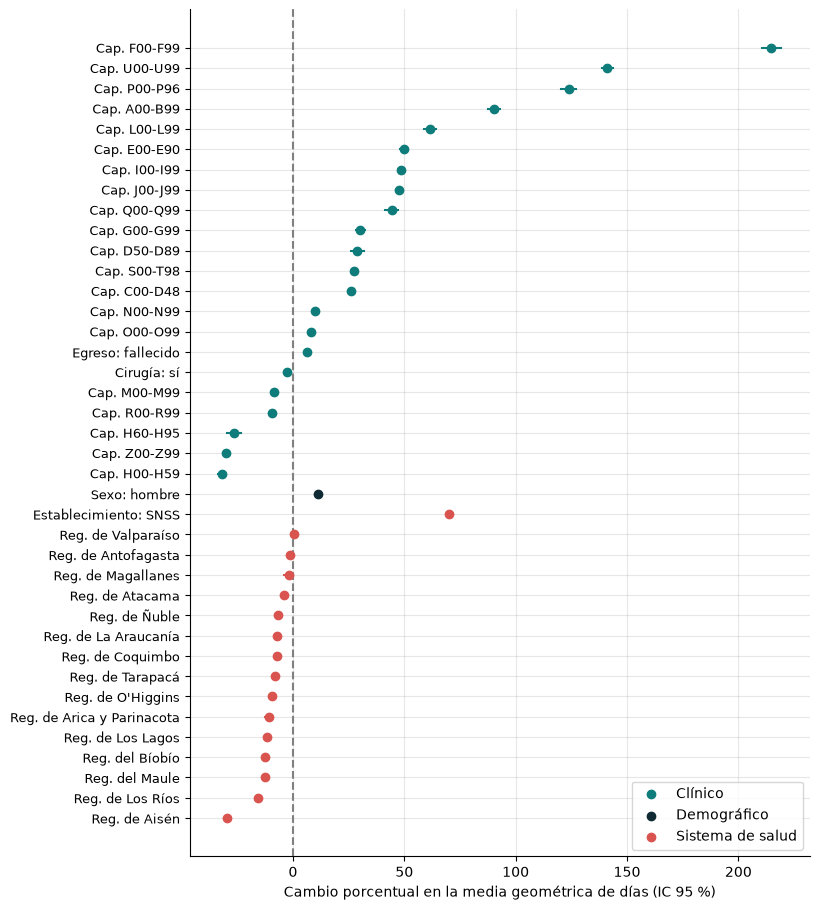

In [18]:
dibujo = coef.drop(["Intercept", "edad_c", "I(edad_c ** 2)"]).copy()
dibujo["bloque"] = np.where(dibujo.index.str.startswith(("capitulo", "cirugia", "fallecido")), "Clínico",
                    np.where(dibujo.index.str.startswith("sexo"), "Demográfico", "Sistema de salud"))
colores = {"Clínico": teal, "Demográfico": petroleo, "Sistema de salud": coral}
dibujo = dibujo.sort_values(["bloque", "%Δ"], ascending=[False, True])

fig, ax = plt.subplots(figsize=(8, 11))
for y, (nombre, fila) in enumerate(dibujo.iterrows()):
    ax.plot([fila["%Δ inf"], fila["%Δ sup"]], [y, y], color=colores[fila["bloque"]])
    ax.scatter(fila["%Δ"], y, color=colores[fila["bloque"]], zorder=3)
ax.axvline(0, color="gray", linestyle="--")
etiquetas = (dibujo.index
    .str.replace("capitulo: ", "Cap. ", regex=False)
    .str.replace("region: De Aisén del Gral. C. Ibáñez del Campo", "Reg. de Aisén", regex=False)
    .str.replace("region: De Magallanes y de La Antártica Chilena", "Reg. de Magallanes", regex=False)
    .str.replace("region: Del Libertador B. O'Higgins", "Reg. de O'Higgins", regex=False)
    .str.replace("region: De La Araucanía", "Reg. de La Araucanía", regex=False)
    .str.replace("region: De ", "Reg. de ", regex=False)
    .str.replace("region: Del ", "Reg. del ", regex=False)
    .str.replace("establecimiento: SNSS", "Establecimiento: SNSS", regex=False)
    .str.replace("sexo: HOMBRE", "Sexo: hombre", regex=False)
    .str.replace("fallecido: Sí", "Egreso: fallecido", regex=False)
    .str.replace("cirugia: Sí", "Cirugía: sí", regex=False))
ax.set_yticks(range(len(dibujo)), etiquetas, fontsize=9)
ax.set_xlabel("Cambio porcentual en la media geométrica de días (IC 95 %)")
for bloque, c in colores.items():
    ax.scatter([], [], color=c, label=bloque)
ax.legend(loc="lower right")
fig.savefig("figures/avance2_analitico/avance2_forest.png", dpi=200, bbox_inches="tight")
plt.show()

El orden de relevancia se obtiene de η² parcial, y la dirección de las asociaciones se lee en los coeficientes. No deben confundirse un cambio porcentual grande entre dos categorías y la proporción de variabilidad atribuible al factor completo.

**Figura 6.** Media observada de ln(días) por tramo de edad y media ajustada por M3 en la base completa.

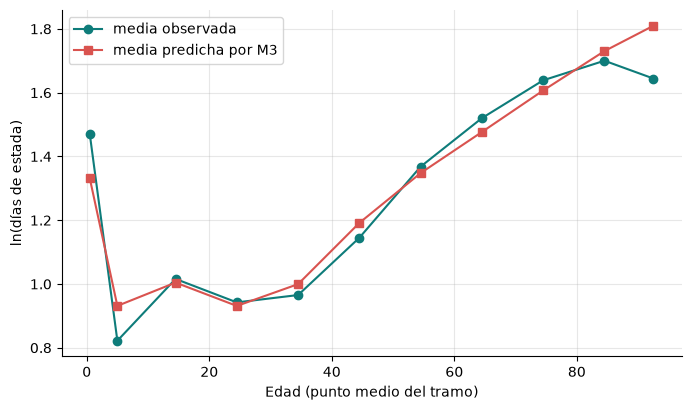

edad      0.5   5.0   14.5  24.5  34.5  44.5  54.5  64.5  74.5  84.5  92.5
log_dias  1.47  0.82  1.02  0.94  0.97  1.15  1.37  1.52  1.64  1.70  1.64
pred      1.33  0.93  1.00  0.93  1.00  1.19  1.35  1.48  1.61  1.73  1.81


In [19]:
df["pred"] = m3.fittedvalues
por_tramo = df.groupby("edad")[["log_dias", "pred"]].mean()
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(por_tramo.index, por_tramo["log_dias"], marker="o", color=teal, label="media observada")
ax.plot(por_tramo.index, por_tramo["pred"], marker="s", color=coral, label="media predicha por M3")
ax.set_xlabel("Edad (punto medio del tramo)")
ax.set_ylabel("ln(días de estada)")
ax.legend()
fig.savefig("figures/avance2_analitico/avance2_edad.png", dpi=200, bbox_inches="tight")
plt.show()
print(por_tramo.round(2).T.to_string())

La comparación por edades permite detectar diferencias sistemáticas entre la forma cuadrática y los promedios observados. Son promedios por grupo que también reflejan su composición diagnóstica; no describen por sí solos un efecto causal de la edad. En 3.8 examinamos una especificación por tramos.

### 3.4 Ajuste global y magnitud de los residuos

Calculamos R² ajustado, MAE y RMSE de ln(días) sobre los mismos egresos usados para estimar M3. En días, el MAE resume la distancia entre los valores observados y exp(ŷ). Es un diagnóstico descriptivo del ajuste, no una estimación del error en casos nuevos. La media geométrica ajustada no necesariamente minimiza el MAE en días.

En la base completa, para menores de un año la media observada de ln(días) es 1,47 y la ajustada 1,33; entre 1 y 9 años son 0,82 y 0,93. En el tramo de 90 años y más, la media observada es 1,64 y la ajustada 1,81. Estas desviaciones en los extremos motivan evaluar edad por tramos en 3.8.


**Tabla 11.** Ajuste de M3 y magnitud de los residuos en la base completa.

In [20]:
df["pred"] = m3.fittedvalues
df["ajustado_dias"] = np.exp(df["pred"])
e = df["log_dias"] - df["pred"]
metricas = pd.DataFrame({"R²": [m3.rsquared], "R² aj.": [m3.rsquared_adj],
    "MAE ln": [e.abs().mean()], "RMSE ln": [np.sqrt((e**2).mean())],
    "MAE días": [(df["dias_estada"] - df["ajustado_dias"]).abs().mean()]}, index=["M3: base completa"])
metricas.round(3)

,R²,R² aj.,MAE ln,RMSE ln,MAE días
M3: base completa,0.198,0.198,0.727,0.927,4.679


R² y los residuos permiten dimensionar cuánto queda sin explicar. Un ajuste parcial puede ser útil para describir asociaciones, aunque no permita determinar la duración individual.

### 3.5 Diagnóstico del ajuste por grupos

Agrupamos los egresos en deciles del valor ajustado y comparamos medias geométricas observadas y ajustadas. Este resumen puede revelar desviaciones sistemáticas; al usar los mismos datos de estimación, no constituye validación independiente.

M3 alcanza R² ajustado = 0,198, RMSE en ln(días) = 0,927 y MAE en días = 4,68. Este último es considerable frente a la mediana observada de 3 días. El hallazgo central es la existencia de asociaciones ajustadas, no la exactitud individual del modelo.


**Tabla 12.** Días ajustados y observados por decil, base completa.

In [21]:
df["decil"] = pd.qcut(df["ajustado_dias"].rank(method="first"), 10, labels=False) + 1
gm = lambda s: np.exp(np.log(s).mean())            # media geométrica de los días
cal = pd.DataFrame({"egresos": df.groupby("decil").size(),
                    "ajustada (media geométrica)": df.groupby("decil")["ajustado_dias"].apply(gm),
                    "observada (media geométrica)": df.groupby("decil")["dias_estada"].apply(gm),
                    "observada (mediana)": df.groupby("decil")["dias_estada"].median()})
cal.round(2)

,egresos,ajustada (media geométrica),observada (media geométrica),observada (mediana)
decil,,,,
1,96810,1.60,1.66,2.0
2,96810,2.21,2.14,2.0
3,96810,2.59,2.50,2.0
4,96809,2.82,2.61,2.0
5,96810,3.11,2.96,3.0
6,96810,3.57,3.67,3.0
7,96809,4.18,4.56,4.0
8,96810,4.88,5.28,5.0
9,96810,5.73,5.99,6.0


**Figura 7.** Medias geométricas ajustadas y observadas por decil en la base completa.

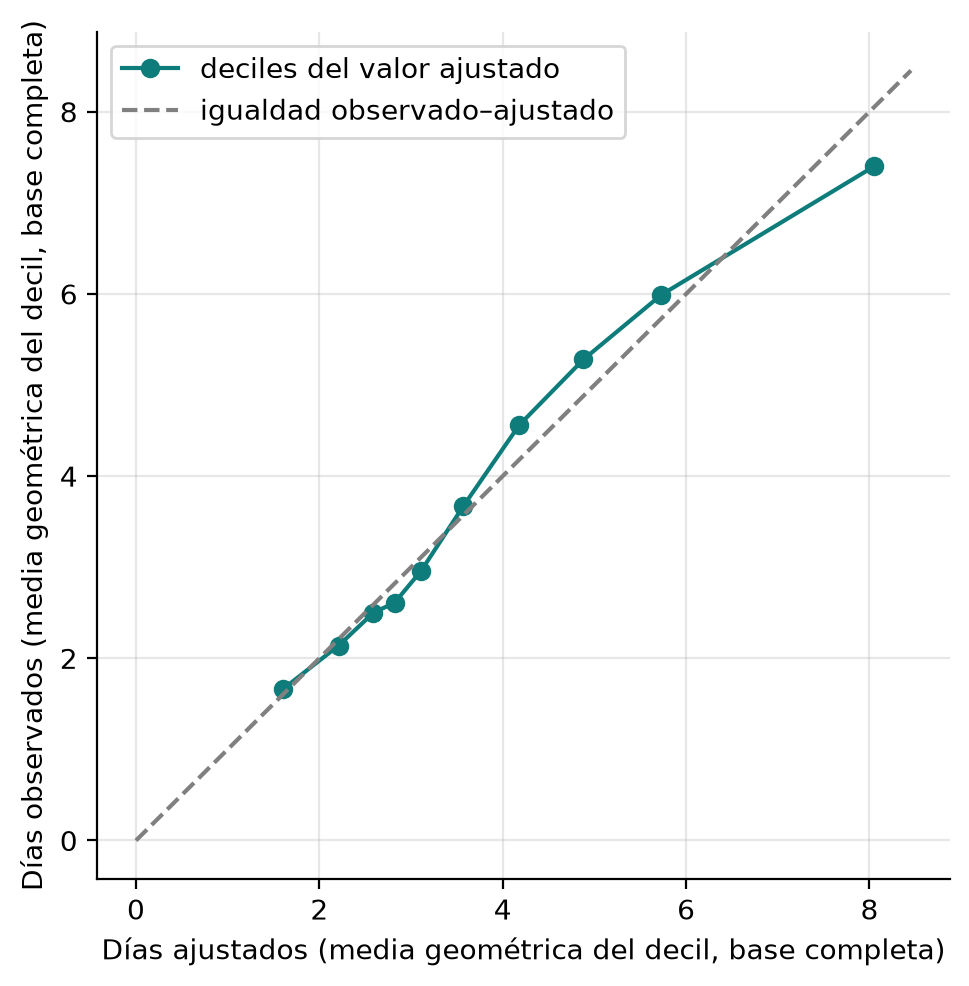

In [22]:
cal_grafico = cal.round(2)
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot(cal_grafico["ajustada (media geométrica)"], cal_grafico["observada (media geométrica)"], marker="o", color=teal, label="deciles del valor ajustado")
lim = [0, cal_grafico[["ajustada (media geométrica)", "observada (media geométrica)"]].max().max() * 1.05]
ax.plot(lim, lim, color="gray", linestyle="--", label="igualdad observado–ajustado")
ax.set_xlabel("Días ajustados (media geométrica del decil, base completa)")
ax.set_ylabel("Días observados (media geométrica del decil, base completa)")
ax.legend()
fig.savefig("figures/avance2_analitico/avance2_calibracion.png", dpi=200, bbox_inches="tight")
plt.show()

Las diferencias respecto de la diagonal muestran grupos que el modelo sobreestima o subestima. Este diagnóstico no establece causalidad ni desempeño fuera de la población analizada.

### 3.6 Supuestos del modelo

Revisamos forma funcional, rango de la matriz de diseño, heterocedasticidad y distribución de residuos. La exogeneidad, E(ε|X)=0, es un supuesto: no se deduce de que los residuos sumen cero. La independencia tampoco se verifica con esta base, porque no identifica pacientes ni hospitales.

Calculamos el VIF con todos los egresos a partir de la matriz de correlaciones de las columnas explicativas. Para los gráficos representamos un subconjunto de puntos por legibilidad; ningún registro se excluye de la estimación o de los diagnósticos numéricos.

En el decil más alto la media geométrica ajustada es 8,05 días y la observada 7,40; en el séptimo son 4,18 y 4,56. Los desvíos tienen ambas direcciones y muestran dónde la especificación resume peor los grupos.


In [23]:
X, r = m3.model.exog, m3.resid.values
pos = np.linspace(0, len(r) - 1, min(20000, len(r)), dtype=int)
# VIF_j = diagonal de la inversa de la correlación entre regresores, sin intercepto.
corr_x = np.corrcoef(X[:, 1:], rowvar=False)
vif = pd.Series(np.diag(np.linalg.inv(corr_x)), index=m3.model.exog_names[1:])
rango_x = np.linalg.matrix_rank(X.T @ X)
print("Rango de X:", rango_x, "de", X.shape[1], "columnas")
print("VIF máximo:", round(vif.max(), 2), "en", vif.idxmax())
print("Media de los residuos:", round(r.mean(), 6))
cuartil = pd.qcut(m3.fittedvalues.rank(method="first"), 4, labels=["Q1", "Q2", "Q3", "Q4"])
print("Desviación de residuos por cuartil:", m3.resid.groupby(cuartil, observed=True).std().round(3).to_dict())
print("Asimetría:", round(stats.skew(r), 3), "| curtosis en exceso:", round(stats.kurtosis(r), 3))

Rango de X: 42 de 42 columnas
VIF máximo: 2.36 en C(capitulo, Treatment('K00-K93'))[T.O00-O99]
Media de los residuos: -0.0
Desviación de residuos por cuartil: {'Q1': 0.713, 'Q2': 0.847, 'Q3': 1.039, 'Q4': 1.061}
Asimetría: 0.492 | curtosis en exceso: 0.542


Un rango completo descarta dependencia lineal exacta y el VIF cuantifica la colinealidad entre regresores. La media residual cero es una identidad del ajuste con intercepto, no una verificación de exogeneidad.

Si la dispersión residual cambia con el valor ajustado, los errores estándar clásicos no son fiables. La heterocedasticidad por sí sola no sesga los coeficientes cuando se cumple exogeneidad, pero aquí la omisión de gravedad también impide asegurar insesgamiento. Posibles reingresos y agrupación por hospital pueden invalidar la independencia. Un gran número de egresos no corrige automáticamente estos problemas.

**Figura 8.** Residuos frente a valores ajustados, histograma y Q-Q. Los puntos se reducen solo para visualización; las estadísticas usan toda la base.

Con la base completa, la matriz tiene rango 42 y el VIF máximo es 2,36, sin indicios de colinealidad severa. La desviación residual aumenta de 0,713 en el primer cuartil de ajustados a 1,061 en el cuarto: la heterocedasticidad persiste. La asimetría residual es 0,492 y la curtosis en exceso 0,542; estas cifras se describen junto con el Q-Q.


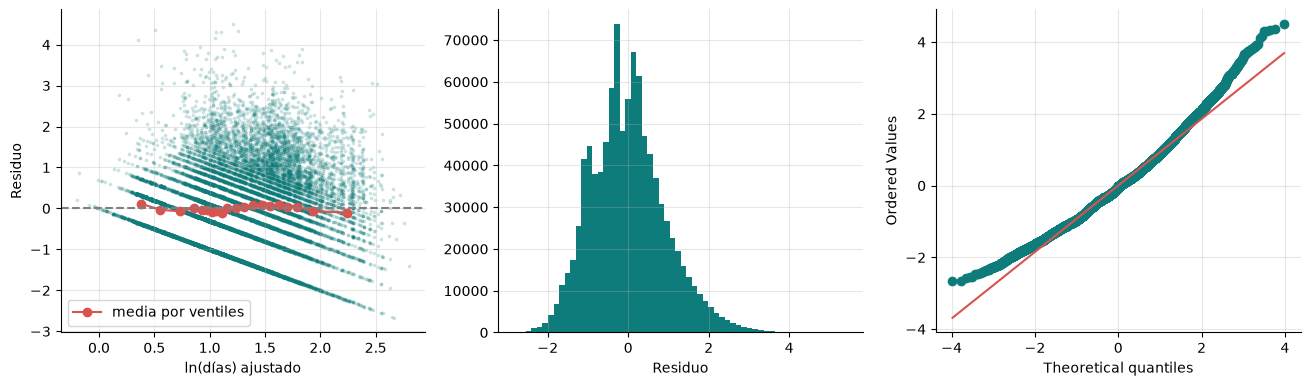

In [24]:
dec = pd.qcut(m3.fittedvalues.rank(method="first"), 20, labels=False)
medias = pd.DataFrame({"ajustado": m3.fittedvalues, "residuo": m3.resid}).groupby(dec).mean()
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
ax[0].scatter(m3.fittedvalues.values[pos[:20000]], r[pos[:20000]], s=3, alpha=0.15, color=teal)
ax[0].plot(medias["ajustado"], medias["residuo"], color=coral, marker="o", label="media por ventiles")
ax[0].axhline(0, color="gray", linestyle="--")
ax[0].set_xlabel("ln(días) ajustado")
ax[0].set_ylabel("Residuo")
ax[0].legend()
ax[1].hist(r, bins=60, color=teal)
ax[1].set_xlabel("Residuo")
stats.probplot(r[pos], plot=ax[2])
ax[2].set_title("")
ax[2].get_lines()[0].set_color(teal)
ax[2].get_lines()[1].set_color(coral)
fig.savefig("figures/avance2_analitico/avance2_residuos.png", dpi=200, bbox_inches="tight")
plt.show()

La curva de residuos medios ayuda a evaluar la forma funcional; la dispersión evalúa la varianza constante y el Q-Q describe desviaciones de normalidad. Las diagonales reflejan que los días son enteros. La inferencia clásica queda condicionada por estos diagnósticos.

### 3.7 Avance 1 contra Avance 2

Comparamos asociaciones bivariadas del Avance 1 con asociaciones ajustadas de M3. Las medidas tienen escalas distintas: interesa la dirección, el orden de relevancia y cuánto cambia la asociación al controlar por otros factores.

**Tabla 13.** Avance 1 contra Avance 2. Fuente: DEIS, MINSAL, egresos hospitalarios 2020; elaboración propia.

In [25]:
d74 = 74.5 - edad_prom
pct_edad = 100 * (np.exp(coef.loc["edad_c", "β"] * d74 + coef.loc["I(edad_c ** 2)", "β"] * d74 ** 2) - 1)
pct_cap = coef.loc[en_cap, "%Δ"]
w_cap, w_reg = ftest.loc["capitulo"], ftest.loc["region"]
print("Edad a los 74,5 años frente a la edad media: %Δ =", round(pct_edad, 1), "%")
def es(x, d=1, signo=False):                      # número con coma decimal y punto de miles
    return f"{x:{'+' if signo else ''},.{d}f}".translate(str.maketrans(",.-", ".,−"))
fmt = lambda nombre: f"{es(coef.loc[nombre, '%Δ'], 1, True)} % [{es(coef.loc[nombre, '%Δ inf'], 1, True)}; {es(coef.loc[nombre, '%Δ sup'], 1, True)}]"
filas = [
    ("Establecimiento (SNSS)", "r = −0,37: el SNSS tiene más días", fmt("establecimiento: SNSS"), "Sigue asociado con más días después de controlar por diagnóstico, edad y región; consultar η² parcial"),
    ("Capítulo CIE-10", "ε² = 0,12; V = 0,25", f"F = {es(w_cap['F'], 0)} (gl = {w_cap['gl']:.0f}); %Δ de {es(pct_cap.min(), 1, True)} a {es(pct_cap.max(), 1, True)} % vs. K00-K93", "Comparar su η² parcial con los demás factores"),
    ("Sexo (hombre vs. mujer)", "r = 0,14: los hombres tienen más días", fmt("sexo: HOMBRE"), "Se mantiene la dirección (los hombres con más días), ahora con el diagnóstico controlado; el η² queda bajo 0,01: consultar η² parcial y contraste"),
    ("Edad", "ρ = 0,25: a más edad, más días", f"{es(pct_edad, 1, True)} % a los 74,5 años vs. la edad media", "Sigue subiendo con la edad, con la curva ajustada casi recta; consultar η² parcial. La parábola no recoge el alza de los menores de un año. ρ es una correlación de rangos de a pares y el % es un cambio ajustado entre dos edades: no son la misma medida"),
    ("Cirugía (sí)", "r = 0,22: los no operados tienen más días (mediana 4 contra 2)", fmt("cirugia: Sí"), "Misma dirección (los operados tienen menos días que los no operados), pero el η² queda bajo 0,01: consultar η² parcial. La diferencia de a pares posiblemente venía del capítulo (capítulo y cirugía tienen V = 0,43)"),
    ("Fallecido (sí)", "r = −0,29: los fallecidos tienen más días", fmt("fallecido: Sí"), "De a pares tenía más días; con el resto controlado el η² queda bajo 0,01: consultar η² parcial. Posiblemente buena parte se asocia con diagnóstico y edad"),
    ("Región", "ε² = 0,002", f"F = {es(w_reg['F'], 1)} (gl = {w_reg['gl']:.0f}); %Δ de {es(coef.loc[en_reg, '%Δ'].min(), 1, True)} a {es(coef.loc[en_reg, '%Δ'].max(), 1, True)} % vs. Santiago", "De a pares casi no se veía y al controlar el η² sigue bajo 0,01: significativa como conjunto, no relevante. Aisén es la más baja"),
]
e2p = {"Establecimiento (SNSS)": "establecimiento", "Capítulo CIE-10": "capítulo", "Sexo (hombre vs. mujer)": "sexo", "Edad": "edad (edad y edad²)",
       "Cirugía (sí)": "cirugía", "Fallecido (sí)": "fallecido", "Región": "región"}
e2txt = lambda nombre: f"{es(parciales.loc[e2p[nombre], 'η² parcial'], 4)} ({parciales.loc[e2p[nombre], 'efecto (Cohen)']})"
tabla = "| Factor | Avance 1 (de a pares, quién tiene más días) | Avance 2 (modelo conjunto, %Δ en la media geométrica [IC 95 %]) | η² parcial (Cohen) | Qué cambia |\n|---|---|---|---|---|\n"
tabla += "\n".join(f"| {a} | {b} | {c} | {e2txt(a)} | {d} |" for a, b, c, d in filas)
display(Markdown(tabla))

Edad a los 74,5 años frente a la edad media: %Δ = 31.1 %


| Factor | Avance 1 (de a pares, quién tiene más días) | Avance 2 (modelo conjunto, %Δ en la media geométrica [IC 95 %]) | η² parcial (Cohen) | Qué cambia |
|---|---|---|---|---|
| Establecimiento (SNSS) | r = −0,37: el SNSS tiene más días | +70,0 % [+69,1; +70,8] | 0,0409 (pequeño) | Sigue asociado con más días después de controlar por diagnóstico, edad y región; consultar η² parcial |
| Capítulo CIE-10 | ε² = 0,12; V = 0,25 | F = 3.867 (gl = 20); %Δ de −31,9 a +214,8 % vs. K00-K93 | 0,0740 (mediano) | Comparar su η² parcial con los demás factores |
| Sexo (hombre vs. mujer) | r = 0,14: los hombres tienen más días | +11,3 % [+10,9; +11,8] | 0,0026 (menor que pequeño) | Se mantiene la dirección (los hombres con más días), ahora con el diagnóstico controlado; el η² queda bajo 0,01: consultar η² parcial y contraste |
| Edad | ρ = 0,25: a más edad, más días | +31,1 % a los 74,5 años vs. la edad media | 0,0347 (pequeño) | Sigue subiendo con la edad, con la curva ajustada casi recta; consultar η² parcial. La parábola no recoge el alza de los menores de un año. ρ es una correlación de rangos de a pares y el % es un cambio ajustado entre dos edades: no son la misma medida |
| Cirugía (sí) | r = 0,22: los no operados tienen más días (mediana 4 contra 2) | −2,8 % [−3,2; −2,3] | 0,0002 (menor que pequeño) | Misma dirección (los operados tienen menos días que los no operados), pero el η² queda bajo 0,01: consultar η² parcial. La diferencia de a pares posiblemente venía del capítulo (capítulo y cirugía tienen V = 0,43) |
| Fallecido (sí) | r = −0,29: los fallecidos tienen más días | +6,3 % [+5,2; +7,3] | 0,0001 (menor que pequeño) | De a pares tenía más días; con el resto controlado el η² queda bajo 0,01: consultar η² parcial. Posiblemente buena parte se asocia con diagnóstico y edad |
| Región | ε² = 0,002 | F = 310,1 (gl = 15); %Δ de −29,8 a +0,3 % vs. Santiago | 0,0048 (menor que pequeño) | De a pares casi no se veía y al controlar el η² sigue bajo 0,01: significativa como conjunto, no relevante. Aisén es la más baja |

Las correlaciones y tamaños de efecto bivariados no son comparables numéricamente con los coeficientes ajustados. La tabla permite distinguir asociaciones que se mantienen de aquellas que se atenúan al incorporar el resto de los factores. Esa atenuación es compatible con información compartida entre variables, pero no prueba un mecanismo causal.

### 3.8 Sensibilidad a la especificación: edad e interacciones

Conservamos M3 como modelo principal para interpretar asociaciones ajustadas y contrastamos tres especificaciones alternativas sobre la base completa:

- M4 sustituye edad y edad² por los 11 tramos de edad, con 40–49 años de referencia. M3 está anidado en M4 porque la edad toma los puntos medios de esos tramos.
- M5 añade capítulo × establecimiento para examinar si la asociación con el establecimiento varía entre diagnósticos.
- M6 añade tramo de edad × establecimiento para examinar heterogeneidad según edad.

Comparamos BIC, F parcial y η² parcial. Un BIC menor indica preferencia relativa dentro de este conjunto; una mejora pequeña no debe interpretarse como relevancia sustantiva. El análisis es exploratorio y no identifica efectos causales.

**Tabla 14.** Comparación de las especificaciones M3 a M6 en la base completa.

In [26]:
tr = "C(tramo_edad, Treatment('40 a 49'))"
f4 = f"log_dias ~ {cap} + C(cirugia) + C(fallecido) + {tr} + C(sexo, Treatment('MUJER')) + C(establecimiento) + {reg}"
f5 = f4 + f" + {cap}:C(establecimiento)"           # M5: capítulo × establecimiento
f6 = f5 + f" + {tr}:C(establecimiento)"             # M6: tramo de edad × establecimiento
cand = [m3] + [smf.ols(f, df).fit() for f in (f4, f5, f6)]
nombres = ["M3", "M4", "M5", "M6"]

filas = []
for i, (n, m) in enumerate(zip(nombres, cand)):
    fila = {"modelo": n, "k": int(m.df_model) + 1, "R² aj.": m.rsquared_adj, "AIC": m.aic, "BIC": m.bic}
    if i > 0:
        a = anova_lm(cand[i - 1], m)
        fila.update({"Δ BIC": m.bic - cand[i - 1].bic, "F parcial": a["F"].iloc[1], "gl": int(a["df_diff"].iloc[1]),
                     "valor-p": a["Pr(>F)"].iloc[1], "η² parcial": (m.rsquared - cand[i - 1].rsquared) / (1 - cand[i - 1].rsquared)})
    filas.append(fila)
tabla_mejoras = pd.DataFrame(filas).set_index("modelo")
tabla_mejoras.round(4)

,k,R² aj.,AIC,BIC,Δ BIC,F parcial,gl,valor-p,η² parcial
modelo,,,,,,,,,
M3,42,0.1980,2.600604e+06,2.601099e+06,NaN,NaN,NaN,NaN,NaN
M4,50,0.2019,2.595922e+06,2.596511e+06,-4587.9818,588.6778,8.0,0.0,0.0048
M5,70,0.2140,2.581149e+06,2.581973e+06,-14537.8842,746.3192,20.0,0.0,0.0152
M6,80,0.2146,2.580368e+06,2.581310e+06,-663.0689,80.1165,10.0,0.0,0.0008


La tabla cuantifica el aporte de cada cambio de especificación. El η² parcial permite distinguir mejoras pequeñas de cambios sustantivos, incluso si los contrastes son significativos. Si las interacciones aportan, la asociación entre establecimiento y duración depende del grupo considerado; el coeficiente de M3 resume esa heterogeneidad.

**Tabla 15.** Ajuste y residuos de M3 a M6 sobre la base completa.

**Comparación recalculada:** M4: R² ajustado = 0,202, ΔBIC = -4.588, η² parcial = 0,0048; M5: R² ajustado = 0,214, ΔBIC = -14.538, η² parcial = 0,0152; M6: R² ajustado = 0,215, ΔBIC = -663, η² parcial = 0,0008. El menor BIC corresponde a M6.


In [27]:
def resume_ajuste(m):
    e = m.resid
    return {"R² aj.": m.rsquared_adj, "MAE ln": e.abs().mean(),
            "RMSE ln": np.sqrt((e**2).mean()),
            "MAE días": (df["dias_estada"] - np.exp(m.fittedvalues)).abs().mean()}
ajuste_especificaciones = pd.DataFrame({nombre: resume_ajuste(m) for nombre, m in zip(nombres, cand)}).T
preferido_bic = nombres[int(np.argmin([m.bic for m in cand]))]
print("Especificación con menor BIC:", preferido_bic)
ajuste_especificaciones.round(3)

Especificación con menor BIC: M6


,R² aj.,MAE ln,RMSE ln,MAE días
M3,0.198,0.727,0.927,4.679
M4,0.202,0.725,0.925,4.671
M5,0.214,0.709,0.918,4.640
M6,0.215,0.709,0.917,4.639


Las diferencias de ajuste describen sensibilidad a la forma funcional. No son evidencia de mejora predictiva externa. M3 se mantiene como referencia para interpretar asociaciones promedio y M4–M6 permiten examinar sus restricciones. La variabilidad restante podría relacionarse con gravedad, comorbilidades u otros factores no observados, pero estos datos no permiten comprobarlo.

**Sensibilidad a la inclusión de nacionalidad y etnia.** El Avance 1 seleccionó siete factores por BIC. Comparamos M3 con una versión que añade nacionalidad y etnia, usando todos los egresos, para evaluar si su exclusión altera apreciablemente el ajuste. Esto no equivale a repetir todo el procedimiento original de selección ni demuestra ausencia de asociación.

**Tabla 16.** M3 y M3 ampliado con nacionalidad y etnia, base completa.

In [28]:
m3x = smf.ols(f3 + " + C(nacionalidad) + C(etnia)", df).fit()
a = anova_lm(m3, m3x)
sensibilidad_variables = pd.DataFrame({"k": [int(m3.df_model) + 1, int(m3x.df_model) + 1], "R² aj.": [m3.rsquared_adj, m3x.rsquared_adj],
                     "BIC": [m3.bic, m3x.bic]}, index=["M3", "M3 + nacionalidad + etnia"])
sensibilidad_variables["F parcial"] = [np.nan, a["F"].iloc[1]]
sensibilidad_variables["valor-p"] = [np.nan, a["Pr(>F)"].iloc[1]]
sensibilidad_variables["η² parcial"] = [np.nan, (m3x.rsquared - m3.rsquared) / (1 - m3.rsquared)]
sensibilidad_variables.round(5)

,k,R² aj.,BIC,F parcial,valor-p,η² parcial
M3,42,0.19799,2.601099e+06,NaN,NaN,NaN
M3 + nacionalidad + etnia,44,0.19800,2.601112e+06,7.49421,0.00056,0.00002


Interpretamos conjuntamente el cambio de BIC, R² ajustado y η² parcial. Si el aporte es pequeño, su exclusión resulta compatible con una especificación parsimoniosa, aunque el contraste sea significativo. Los contrastes posteriores a selección de variables tienen un alcance exploratorio.

Al incorporar nacionalidad y etnia, ΔBIC = 12,6 y η² parcial = 0,00002. El BIC favorece conservar M3, pero el tamaño del aporte queda por debajo de 0,01. Esta comparación describe la sensibilidad del ajuste y no altera el foco interpretativo en los siete factores originales.


### 3.9 Asociaciones con la estadía prolongada: regresión logística

La respuesta es la ocurrencia de más de 15 días de estada. Ajustamos modelos logísticos anidados con los siete factores y edad en tramos, sobre la misma base completa. El interés principal son los cocientes de odds ajustados (OR), sus intervalos y el aporte de cada factor al ajuste. No se busca construir una regla de clasificación ni una herramienta para decidir al ingreso.

**Tabla 17.** Modelos logísticos anidados. L1: factores clínicos; L2: añade edad y sexo; L3: añade establecimiento y región. Pseudo-R² de McFadden = 1 − log-verosimilitud del modelo / log-verosimilitud del modelo nulo; no es proporción de varianza explicada.

In [29]:
from scipy.stats import rankdata

df["y"] = (df["dias_estada"] > 15).astype(int)      # estadía prolongada: más de 15 días

sx = "C(sexo, Treatment('MUJER'))"
partes = {"capítulo": cap, "cirugía": "C(cirugia)", "fallecido": "C(fallecido)", "edad (tramos)": tr, "sexo": sx,
          "establecimiento": "C(establecimiento)", "región": reg}
def formula(sin=None):
    return "y ~ " + " + ".join(t for n, t in partes.items() if n != sin)

bloques_l = [("L0", "y ~ 1"), ("L1", "y ~ " + " + ".join([cap, "C(cirugia)", "C(fallecido)"])),
             ("L2", "y ~ " + " + ".join([cap, "C(cirugia)", "C(fallecido)", tr, sx])), ("L3", formula())]
ajustes = [smf.logit(f, df).fit(disp=0) for _, f in bloques_l]
filas = []
for i, ((n, _), m) in enumerate(zip(bloques_l, ajustes)):
    fila = {"modelo": n, "k": int(m.df_model) + 1, "devianza": -2 * m.llf, "AIC": m.aic, "BIC": m.bic, "D² McFadden": m.prsquared}
    if i > 0:
        lr = 2 * (m.llf - ajustes[i - 1].llf)
        gl = int(m.df_model - ajustes[i - 1].df_model)
        fila.update({"χ² (RV)": lr, "gl": gl, "valor-p": stats.chi2.sf(lr, gl), "Δ BIC": m.bic - ajustes[i - 1].bic})
    filas.append(fila)
tabla_logit = pd.DataFrame(filas).set_index("modelo")
tabla_logit.round(4)

,k,devianza,AIC,BIC,D² McFadden,χ² (RV),gl,valor-p,Δ BIC
modelo,,,,,,,,,
L0,1,603086.5066,603088.5066,603100.2897,0.0000,NaN,NaN,NaN,NaN
L1,23,538997.9855,539043.9855,539314.9966,0.1063,64088.5210,22.0,0.0,-63785.2931
L2,34,530220.5478,530288.5478,530689.1728,0.1208,8777.4377,11.0,0.0,-8625.8238
L3,50,522398.9498,522498.9498,523088.1043,0.1338,7821.5980,16.0,0.0,-7601.0686


La razón de verosimilitud evalúa el aporte de cada bloque, mientras BIC pondera ajuste y complejidad. El pseudo-R² de McFadden no se compara directamente con R² de la regresión lineal.

Para evaluar aportes ajustados retiramos cada factor de L3. Como diagnóstico complementario calculamos AUC aparente sobre la base completa; no corresponde a validación externa.

**Tabla 18.** Razón de verosimilitud y caída del pseudo-R² al retirar cada factor.

L3 alcanza un pseudo-R² de McFadden de 0,134. El aporte de los bloques se cuantifica con las razones de verosimilitud de la tabla 17; el orden de relevancia de factores se evalúa a continuación mediante su retirada individual.


In [30]:
def auc(y, p):                                          # AUC por la suma de rangos (Mann-Whitney)
    r = rankdata(p)
    n1 = y.sum()
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * (len(y) - n1))

l3 = ajustes[3]
prob_ajustada = l3.predict(df)
auc_aparente = auc(df["y"].values, prob_ajustada.values)

filas = []
for n in partes:                                        # sacamos un factor a la vez
    m = smf.logit(formula(n), df).fit(disp=0)
    lr = 2 * (l3.llf - m.llf)
    gl = int(l3.df_model - m.df_model)
    filas.append({"factor": n, "χ² (RV)": lr, "gl": gl, "valor-p": stats.chi2.sf(lr, gl),
                  "caída del D² de McFadden": l3.prsquared - m.prsquared})
delta_d2 = pd.DataFrame(filas).set_index("factor").sort_values("χ² (RV)", ascending=False)
print("AUC aparente:", round(auc_aparente, 4), "| prevalencia:", round(df["y"].mean(), 4))
delta_d2.round(4)

AUC aparente: 0.7694 | prevalencia: 0.0939


,χ² (RV),gl,valor-p,caída del D² de McFadden
factor,,,,
capítulo,35610.0514,20,0.0,0.0590
edad (tramos),7745.3848,10,0.0,0.0128
establecimiento,5912.3220,1,0.0,0.0098
región,2881.6260,15,0.0,0.0048
fallecido,1587.4980,1,0.0,0.0026
sexo,1065.4685,1,0.0,0.0018
cirugía,1036.1066,1,0.0,0.0017


La caída del pseudo-R² al retirar cada factor permite ordenar su aporte ajustado. No es un tamaño de efecto causal ni comparte la escala de Cohen. El AUC aparente describe separación entre egresos con y sin estadía prolongada en los datos usados para ajustar el modelo; no evalúa desempeño en otros egresos.

Los mayores aportes corresponden a capítulo (caída = 0,0590), edad (tramos) (caída = 0,0128), establecimiento (caída = 0,0098). El AUC aparente es 0,769 y se mantiene como diagnóstico secundario.


In [31]:
print("Egresos analizados:", len(df))
print("Estadías prolongadas:", int(df["y"].sum()))
print("Proporción observada:", round(df["y"].mean(), 4))
print("Promedio de probabilidad ajustada:", round(prob_ajustada.mean(), 4))

Egresos analizados: 968098
Estadías prolongadas: 90909
Proporción observada: 0.0939
Promedio de probabilidad ajustada: 0.0939


Los OR comparan las odds de estadía prolongada entre categorías, manteniendo constantes los demás factores. Un OR de 2 implica el doble de odds, no necesariamente el doble de probabilidad. Los intervalos de Wald asumen la especificación y la independencia de las observaciones.

**Tabla 19.** OR ajustados de L3 e IC del 95 %. Se muestran factores binarios, capítulos extremos y tramos de edad.

In [32]:
ic = l3.conf_int()
orr = pd.DataFrame({"OR": np.exp(l3.params), "IC inf": np.exp(ic[0]), "IC sup": np.exp(ic[1]), "valor-p": l3.pvalues})
orr.index = orr.index.str.replace(r"C\((\w+)[^\[]*\[T\.(.*)\]", r"\1: \2", regex=True)
en_capl = orr.index[orr.index.str.startswith("capitulo")]
extremos = list(orr.loc[en_capl, "OR"].nlargest(3).index) + list(orr.loc[en_capl, "OR"].nsmallest(1).index)
tramos = list(orr.index[orr.index.str.startswith("tramo")])
orr.loc[["cirugia: Sí", "fallecido: Sí", "sexo: HOMBRE", "establecimiento: SNSS"] + extremos + tramos].round(3)

,OR,IC inf,IC sup,valor-p
cirugia: Sí,1.359,1.334,1.385,0.0
fallecido: Sí,1.762,1.715,1.810,0.0
sexo: HOMBRE,1.277,1.258,1.296,0.0
establecimiento: SNSS,2.539,2.474,2.606,0.0
capitulo: F00-F99,13.014,12.497,13.552,0.0
capitulo: U00-U99,4.585,4.429,4.746,0.0
capitulo: A00-B99,3.852,3.679,4.032,0.0
capitulo: O00-O99,0.263,0.249,0.278,0.0
tramo_edad: 1 a 9,0.423,0.401,0.446,0.0
tramo_edad: 10 a 19,0.678,0.649,0.708,0.0


Los OR muestran la dirección y magnitud de la asociación con la estadía prolongada. Se interpretan junto con la caída del pseudo-R²: un OR grande para una categoría no implica que el factor explique gran parte del fenómeno. La duración en escala logarítmica y superar 15 días son respuestas distintas; sus asociaciones pueden diferir sin contradicción.

**Figura 9.** Curva ROC aparente y proporciones observadas frente a probabilidades ajustadas por decil en la base completa.

**OR ajustados:** SNSS: 2,54 (IC 95 %: 2,47–2,61); fallecido al egreso: 1,76 (IC 95 %: 1,71–1,81); cirugía: 1,36 (IC 95 %: 1,33–1,38); hombre: 1,28 (IC 95 %: 1,26–1,30); trastornos mentales frente a digestivo: 13,01 (IC 95 %: 12,50–13,55). Las magnitudes describen asociaciones condicionadas al resto de los factores y no efectos de intervenciones.


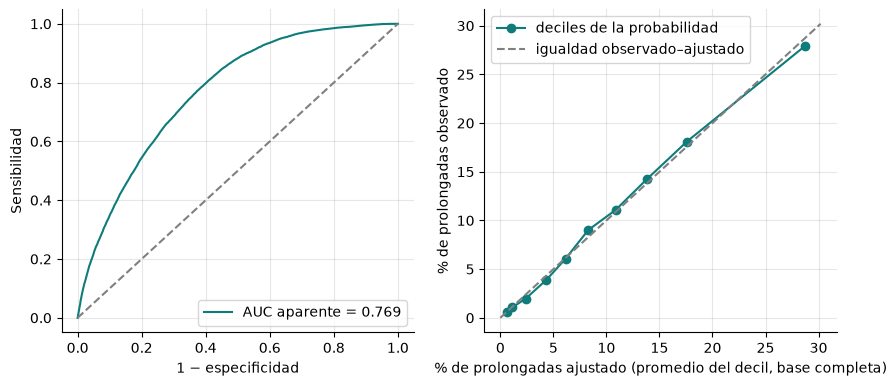

        0    1    2    3    4    5     6     7     8     9
pred  0.6  1.1  2.4  4.3  6.1  8.3  10.9  13.8  17.6  28.8
obs   0.6  1.1  2.0  3.9  6.1  9.0  11.1  14.2  18.1  27.9


In [33]:
o = np.argsort(-prob_ajustada.values)
yy = df["y"].values[o]
tpr, fpr = np.cumsum(yy) / yy.sum(), np.cumsum(1 - yy) / (1 - yy).sum()
dec = pd.qcut(prob_ajustada.rank(method="first"), 10, labels=False)
cal_l = pd.DataFrame({"pred": prob_ajustada, "obs": df["y"]}).groupby(dec).mean() * 100

fig, ax = plt.subplots(1, 2, figsize=(10, 4.2))
ax[0].plot(fpr[::200], tpr[::200], color=teal, label=f"AUC aparente = {auc_aparente:.3f}")
ax[0].plot([0, 1], [0, 1], color="gray", linestyle="--")
ax[0].set_xlabel("1 − especificidad")
ax[0].set_ylabel("Sensibilidad")
ax[0].legend(loc="lower right")
ax[1].plot(cal_l["pred"], cal_l["obs"], marker="o", color=teal, label="deciles de la probabilidad")
lim = [0, cal_l.max().max() * 1.05]
ax[1].plot(lim, lim, color="gray", linestyle="--", label="igualdad observado–ajustado")
ax[1].set_xlabel("% de prolongadas ajustado (promedio del decil, base completa)")
ax[1].set_ylabel("% de prolongadas observado")
ax[1].legend(loc="upper left")
fig.savefig("figures/avance2_analitico/avance2_roc.png", dpi=200, bbox_inches="tight")
plt.show()
print(cal_l.round(1).T.to_string())

La concordancia por deciles describe el ajuste agregado en la población analizada. No garantiza precisión individual, transportabilidad a otro año ni utilidad clínica. La condición de egreso se conoce al alta: el modelo describe asociaciones retrospectivas.

### 3.10 Selección forward de factores para el modelo de duración

El profesor pidió mostrar una selección de variables paso a paso. La aplicamos a la regresión lineal de ln(días) sobre los mismos 968.098 egresos, usando **BIC** como criterio de entrada y parada. Partimos del intercepto; en cada paso probamos añadir cada factor aún ausente, elegimos el modelo con menor BIC y nos detenemos si ninguno mejora el BIC anterior. Un factor categórico entra con todas sus indicadoras y la edad entra con sus dos términos para respetar la estructura de M3.

Calculamos los ajustes candidatos a partir de los productos cruzados de la matriz de diseño de M3. Para cada subconjunto, resolver las ecuaciones normales reproduce el ajuste OLS de esas columnas sin reconstruir una matriz de casi un millón de filas en cada paso. Contrastamos el resultado final con M3 para verificar la equivalencia numérica. Esta búsqueda es exploratoria y dependiente del criterio BIC; los valores-p posteriores a la selección no son pruebas confirmatorias independientes.

**Tabla 20.** Recorrido forward por factores: BIC, R² ajustado y aporte del factor incorporado.

In [34]:
# Selección forward por factores completos del modelo M3.
from scipy.stats import f as dist_f

factores_forward = {
    "capítulo": cap,
    "cirugía": "C(cirugia)",
    "condición de egreso": "C(fallecido)",
    "edad y edad²": ["edad_c", "I(edad_c ** 2)"],
    "sexo": "C(sexo, Treatment('MUJER'))",
    "establecimiento": "C(establecimiento)",
    "región": reg,
}
nombres_columnas = m3.model.exog_names
columnas_factor = {}
for nombre, termino in factores_forward.items():
    if isinstance(termino, str): termino = [termino]
    columnas_factor[nombre] = [j for t in termino for j, col in enumerate(nombres_columnas) if col == t or col.startswith(t + "[")]
assert set(sum(columnas_factor.values(), [0])) == set(range(m3.model.exog.shape[1]))

X_forward = m3.model.exog
y_forward = m3.model.endog
gram = X_forward.T @ X_forward
xy = X_forward.T @ y_forward
yy = y_forward @ y_forward
n_forward = len(y_forward)
tss_forward = m3.centered_tss
def evaluar_factores(nombres):
    cols = [0] + [j for nombre in nombres for j in columnas_factor[nombre]]
    beta = np.linalg.solve(gram[np.ix_(cols, cols)], xy[cols])
    sse = yy - beta @ xy[cols]
    k = len(cols)
    bic = n_forward * (np.log(2*np.pi) + 1 + np.log(sse/n_forward)) + k*np.log(n_forward)
    r2 = 1 - sse/tss_forward
    r2_aj = 1 - (1-r2)*(n_forward-1)/(n_forward-k)
    return {"SSE":sse,"k":k,"BIC":bic,"R² ajustado":r2_aj}

seleccionados=[]
actual=evaluar_factores(seleccionados)
pasos_forward=[{"paso":0,"entra":"intercepto","factores incluidos":"—",**actual,"ΔBIC":np.nan,"F parcial":np.nan,"valor-p":np.nan}]
alternativas_forward=[]
for paso in range(1,len(factores_forward)+1):
    opciones=[(nombre,evaluar_factores(seleccionados+[nombre])) for nombre in factores_forward if nombre not in seleccionados]
    opciones.sort(key=lambda item:item[1]["BIC"])
    elegido,nuevo=opciones[0]
    alternativas_forward.append({"paso":paso,"opciones BIC":{nombre:fit["BIC"] for nombre,fit in opciones}})
    if nuevo["BIC"] >= actual["BIC"]: break
    gl=nuevo["k"]-actual["k"]
    F=((actual["SSE"]-nuevo["SSE"])/gl)/(nuevo["SSE"]/(n_forward-nuevo["k"]))
    seleccionados.append(elegido)
    pasos_forward.append({"paso":paso,"entra":elegido,"factores incluidos":", ".join(seleccionados),
                          **nuevo,"ΔBIC":nuevo["BIC"]-actual["BIC"],"F parcial":F,
                          "valor-p":dist_f.sf(F,gl,n_forward-nuevo["k"])})
    actual=nuevo

tabla_forward=pd.DataFrame(pasos_forward).set_index("paso")
assert abs(evaluar_factores(list(factores_forward))["BIC"]-m3.bic)<0.1
print("Factores seleccionados:", ", ".join(seleccionados))
print("Factores descartados:", ", ".join(n for n in factores_forward if n not in seleccionados) or "ninguno")
tabla_forward_mostrar=tabla_forward.drop(columns="SSE").copy()
tabla_forward_mostrar["valor-p"] = tabla_forward_mostrar["valor-p"].map(lambda p: "?" if pd.isna(p) else ("<0,001" if p<0.001 else f"{p:.3f}"))
tabla_forward_mostrar.round(3)

Factores seleccionados: capítulo, establecimiento, edad y edad², región, sexo, cirugía, condición de egreso
Factores descartados: ninguno


,entra,factores incluidos,k,BIC,R² ajustado,ΔBIC,F parcial,valor-p
0,intercepto,—,1,2814165.529,-0.000,NaN,NaN,?
1,capítulo,capítulo,21,2685110.586,0.125,-129054.944,6918.215,"<0,001"
2,establecimiento,"capítulo, establecimiento",22,2643746.264,0.162,-41364.321,42274.162,"<0,001"
3,edad y edad²,"capítulo, establecimiento, edad y edad²",24,2608361.699,0.192,-35384.566,18033.440,"<0,001"
4,región,"capítulo, establecimiento, edad y edad², región",39,2603932.090,0.196,-4429.609,309.819,"<0,001"
5,sexo,"capítulo, establecimiento, edad y edad², región, sexo",40,2601374.303,0.198,-2557.787,2574.882,"<0,001"
6,cirugía,"capítulo, establecimiento, edad y edad², región, sexo, cirugía",41,2601224.127,0.198,-150.176,163.966,"<0,001"
7,condición de egreso,"capítulo, establecimiento, edad y edad², región, sexo, cirugía, condición de egreso",42,2601099.216,0.198,-124.911,138.698,"<0,001"


El recorrido muestra el orden de incorporación y cuánto baja el BIC en cada paso. El F parcial describe el incremento de ajuste entre dos modelos anidados; no sustituye el criterio de parada, que aquí es BIC.

**Tabla 21.** Comparación del modelo elegido por forward con M3 completo.

**Resultado.** El recorrido incorpor?, en orden, cap?tulo, establecimiento, edad con edad?, regi?n, sexo, cirug?a y condici?n de egreso. Los siete pasos redujeron el BIC. Por eso, bajo este criterio, no se descarta ning?n factor y el modelo final coincide con M3. El mayor descenso ocurri? al incorporar cap?tulo (?BIC = ?129.055); los menores fueron cirug?a (?150) y condici?n de egreso (?125).


In [35]:
comparacion_forward=pd.DataFrame([
    {"modelo":"forward", "factores":len(seleccionados),**{k:actual[k] for k in ["k","BIC","R² ajustado"]}},
    {"modelo":"M3 completo", "factores":len(factores_forward),"k":int(m3.df_model)+1,
     "BIC":m3.bic,"R² ajustado":m3.rsquared_adj},
]).set_index("modelo")
comparacion_forward["ΔBIC vs. M3"] = comparacion_forward["BIC"]-m3.bic
comparacion_forward.round(4)

,factores,k,BIC,R² ajustado,ΔBIC vs. M3
modelo,,,,,
forward,7,42,2.601099e+06,0.198,0.0
M3 completo,7,42,2.601099e+06,0.198,0.0


La selección por BIC se interpreta junto con el aporte ajustado de cada factor, los coeficientes de M3 y los límites del estudio. Si el recorrido conserva los siete factores, el resultado no implica que todos sean igualmente importantes: BIC puede retener diferencias muy pequeñas con este tamaño de base. Si elimina alguno, la comparación cuantifica el costo de simplificar el modelo. En cualquier caso, la selección no establece causalidad ni valida el modelo fuera de 2020.

En esta base, forward conserva los siete factores y reproduce exactamente el BIC y R? ajustado de M3. El resultado confirma que M3 es preferido entre los modelos recorridos por el algoritmo. No demuestra que sea el mejor de los 127 subconjuntos posibles ni que los siete factores tengan igual relevancia. Los ?? parciales de cap?tulo, establecimiento y edad siguen siendo los m?s altos; cirug?a y condici?n de egreso son menores que 0,001.


## 4. Discusión y conclusiones

### 4.1 Hallazgos y alcance

La sección 3.10 agrega la selección forward pedida en clase y la compara con M3.

Los modelos permiten estudiar por separado la duración en escala logarítmica y la ocurrencia de estadías prolongadas. Las tablas de coeficientes y OR describen asociaciones ajustadas; η² parcial y la caída del pseudo-R² distinguen magnitud estadística de mera significación. El resumen numérico siguiente se genera directamente desde los modelos estimados sobre la base completa.

**Respuesta a la pregunta de investigación.** El capítulo diagnóstico, el tipo de establecimiento y la edad son los factores con mayor aporte ajustado a la duración. En M3, sus η² parciales son 0,074, 0,041 y 0,035, respectivamente. En la estadía prolongada, el diagnóstico también encabeza el aporte al ajuste; SNSS presenta OR = 2,54. Las asociaciones respaldan los componentes clínico, demográfico y del sistema de salud de las hipótesis, bajo las limitaciones de la inferencia descritas.

Sexo, cirugía, condición de egreso y región tienen aportes menores a la duración según η² parcial. Para estadía prolongada la condición de egreso presenta OR = 1,76, lo que muestra por qué conviene analizar ambas respuestas. Las alternativas de edad e interacciones modifican el ajuste, pero no convierten estas asociaciones en explicaciones causales. La información disponible deja gran parte de la variabilidad sin explicar.

### 4.2 Relación con las hipótesis

H1a se examina mediante diagnóstico, cirugía y condición de egreso; H1b mediante edad y sexo, con nacionalidad y etnia como sensibilidad; H1c mediante establecimiento y región. Evidencia de asociación en un factor respalda la hipótesis del bloque, sin implicar que todos sus componentes sean relevantes. Para la duración usamos α = 0,05 y η² parcial ≥ 0,01 como criterio orientativo; para la prolongada interpretamos OR, intervalos y aportes al ajuste. Las decisiones inferenciales quedan condicionadas por heterocedasticidad, dependencia potencial y selección previa.

### 4.3 Relación con la literatura

El papel del diagnóstico se discute en relación con la lógica de los GRD (Fetter et al., 1980). Freitas et al. (2012) estudian edad y establecimiento en estadías extremas en Portugal; Olivares-Tirado (2020) analiza hospitalización prolongada en adultos mayores de Chile. Las diferencias de población, período y definición impiden equiparar directamente las magnitudes. BIC aporta un criterio de parsimonia (Raftery, 1995); con grandes bases es esencial informar tamaños de efecto junto con valores-p (Lin et al., 2013).

### 4.4 Posibles explicaciones

El tipo de establecimiento puede recoger diferencias de gravedad o complejidad no observadas. Edad y diagnóstico también pueden relacionarse con necesidades de atención distintas. Son explicaciones plausibles que no se prueban aquí. Las interacciones examinan heterogeneidad de asociaciones, no mecanismos causales.

### 4.5 Limitaciones

- La unidad es el egreso: posibles reingresos y agrupación por hospital cuestionan la independencia.
- No contamos con gravedad, GRD, comorbilidades completas ni identificadores para separar estas fuentes de variación. Persiste confusión no observada.
- La edad procede de tramos; cambiar su parametrización no recupera diferencias dentro de ellos.
- Los errores estándar clásicos de M3 son sensibles a heterocedasticidad; la inferencia se presenta con esa limitación.
- El filtro de 365 días mantiene la definición del Avance 1, pero puede excluir estadías legítimas excepcionalmente largas. No se ha realizado un análisis de sensibilidad a ese umbral.
- Las comparaciones de especificación y la selección previa hacen que parte del análisis sea exploratorio.
- Los datos corresponden a 2020, primer año de pandemia. Las asociaciones no se extrapolan automáticamente a otros años.
- La condición de egreso se conoce al alta. Estos modelos no son herramientas de decisión al ingreso.
- Usar todos los egresos evita reservar observaciones para una tarea predictiva ajena al objetivo, pero no elimina sesgos de selección, medición o confusión. Las medidas de ajuste corresponden a esta misma base.

### 4.6 Implicancias

El estudio permite caracterizar grupos con mayor duración o mayores odds de estadía prolongada y distinguir qué asociaciones persisten al ajustar por otros factores. Puede orientar preguntas sobre utilización de camas y diferencias entre grupos, sin atribuir causalidad ni establecer decisiones individuales. Incorporar gravedad, GRD e identificadores de paciente y hospital permitiría profundizar el análisis.

### Síntesis numérica y cifras para la presentación

El resumen y el archivo de resultados siguientes se generan a partir de los ajustes sobre la base completa, para mantener consistencia entre cifras y relato.

In [36]:
def num(o):
    return o.item() if hasattr(o, "item") else str(o)

resumen = f"""**Resultados sobre {len(df):,} egresos.** M3: R² ajustado = {m3.rsquared_adj:.3f}; M6: R² ajustado = {cand[-1].rsquared_adj:.3f}. La especificación con menor BIC es {preferido_bic}. Estos valores describen el ajuste en la base completa.

**Duración:** los tres factores con mayor η² parcial son {', '.join(f'{idx} ({row["η² parcial"]:.3f})' for idx, row in parciales.sort_values('η² parcial', ascending=False).head(3).iterrows())}. El cambio ajustado asociado a SNSS es {coef.loc['establecimiento: SNSS', '%Δ']:.1f} % en media geométrica; para hombres frente a mujeres es {coef.loc['sexo: HOMBRE', '%Δ']:.1f} %.

**Estadía prolongada:** prevalencia = {100*df['y'].mean():.1f} %. OR de SNSS = {orr.loc['establecimiento: SNSS','OR']:.2f} (IC 95 %: {orr.loc['establecimiento: SNSS','IC inf']:.2f}–{orr.loc['establecimiento: SNSS','IC sup']:.2f}). Pseudo-R² de McFadden de L3 = {l3.prsquared:.3f}; AUC aparente = {auc_aparente:.3f}. No son resultados de validación independiente."""
display(Markdown(resumen))
cifras = {
    "enfoque": "analítico, observacional, base completa, sin particiones",
    "n": len(df), "excluidos_mas_365": int((bruta > 365).sum()),
    "base_analitica": base_analitica.to_dict("index"),
    "descriptivos": desc.round(4).to_dict("index"),
    "pct_prolongadas": pct_egresos, "pct_dias_cama": pct_dias,
    "atipicos": atip.round(4).to_dict("index"), "comparacion_robustez": comp.round(4).to_dict("index"),
    "pct_diag2_nulo": pct_diag2,
    "modelos": tabla_modelos.round(6).to_dict("index"), "anova": anova.round(6).to_dict("index"),
    "coef": coef.round(5).to_dict("index"), "ftest": ftest.round(5).to_dict("index"),
    "ajuste_base_completa": metricas.round(5).to_dict("index"), "vif_max": vif.max(), "rango_X": int(rango_x),
    "eta2_bloques": bloques.set_index("comparación").round(6).to_dict("index"),
    "eta2_parciales": parciales.round(6).to_dict("index"),
    "especificaciones": tabla_mejoras.round(5).to_dict("index"),
    "forward_pasos": tabla_forward.round(6).to_dict("index"),
    "forward_comparacion": comparacion_forward.round(6).to_dict("index"),
    "forward_factores": seleccionados,
    "ajuste_especificaciones": ajuste_especificaciones.round(5).to_dict("index"),
    "especificacion_menor_bic": preferido_bic,
    "sensibilidad_variables": sensibilidad_variables.round(6).to_dict("index"),
    "logit_bloques": tabla_logit.round(6).to_dict("index"), "logit_auc_aparente": auc_aparente,
    "logit_delta_d2": delta_d2.round(6).to_dict("index"), "logit_or": orr.round(5).to_dict("index"),
}
os.makedirs("results", exist_ok=True)
with open("results/cifras_avance2_analitico.json", "w", encoding="utf-8") as f:
    json.dump(cifras, f, default=num, ensure_ascii=False, indent=2)
print("Cifras guardadas:", len(cifras), "claves")

**Resultados sobre 968,098 egresos.** M3: R² ajustado = 0.198; M6: R² ajustado = 0.215. La especificación con menor BIC es M6. Estos valores describen el ajuste en la base completa.

**Duración:** los tres factores con mayor η² parcial son capítulo (0.074), establecimiento (0.041), edad (edad y edad²) (0.035). El cambio ajustado asociado a SNSS es 70.0 % en media geométrica; para hombres frente a mujeres es 11.3 %.

**Estadía prolongada:** prevalencia = 9.4 %. OR de SNSS = 2.54 (IC 95 %: 2.47–2.61). Pseudo-R² de McFadden de L3 = 0.134; AUC aparente = 0.769. No son resultados de validación independiente.

Cifras guardadas: 30 claves


## Referencias


1. Cohen, J. (1988). *Statistical power analysis for the behavioral sciences* (2.ª ed.). Lawrence Erlbaum Associates.
2. Fetter, R. B., Shin, Y., Freeman, J. L., Averill, R. F., & Thompson, J. D. (1980). Case mix definition by diagnosis-related groups. *Medical Care, 18*(2 Suppl.), 1–53.
3. Freitas, A., Silva-Costa, T., Lopes, F., Garcia-Lema, I., Teixeira-Pinto, A., Brazdil, P., & Costa-Pereira, A. (2012). Factors influencing hospital high length of stay outliers. *BMC Health Services Research, 12*, Article 265. https://doi.org/10.1186/1472-6963-12-265
4. Lin, M., Lucas, H. C., & Shmueli, G. (2013). Too big to fail: Large samples and the p-value problem. *Information Systems Research, 24*(4), 906–917. https://doi.org/10.1287/isre.2013.0480
5. Olivares-Tirado, P. (2020). *Hospitalización social en adultos mayores en el sistema de salud de Chile* [Documento de trabajo]. Superintendencia de Salud. https://www.superdesalud.gob.cl/biblioteca-digital/hospitalizacion-social-en-adultos-mayores-en-el-sistema-de-salud-de-chile/
6. Raftery, A. E. (1995). Bayesian model selection in social research. *Sociological Methodology, 25*, 111–163. https://doi.org/10.2307/271063
7. Rodríguez, D. E., & González, G. J. (2017). *Principios de econometría*. Fondo Editorial ITM.